# Этап III. Как нормировка меняет вибрационные сигналы

**Исследовательский вопрос:** какие способы уменьшения различий масштаба сохраняют потенциально полезную информацию о неисправностях?

Мы сравниваем шесть преобразований на **17 реальных рядах пяти датасетов**. Это описательное исследование малой выборки, а не оценка классификатора. Этап II завершён: читаем готовые массивы 51 200 Гц без повторного ресемплинга, фильтрации и обучения.

**Запуск:** выберите существующее окружение проекта, в котором выполнено `python -m pip install -e ".[dev]"`, затем Run All. Код не изменяет файлы этапов I–II. Создаются только результаты этапа III. Пакет импортируется штатно, без `sys.path`.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from cos1.data import ROOT
from cos1.analysis import statistics
from cos1.normalization import (
    METHODS, Parameters, apply, fit_individual, mean_square_spectrum,
)
from cos1.spectrum import amplitude_spectrum
from cos1.normalization_study import (
    load_study, fit_common, evaluate, compare_states, comparison_figure,
    save_figure, write_results, report_text,
)

# ROOT определяется расположением установленного пакета, а не текущей папкой Notebook.
ROOT = Path(ROOT)
print("Интерпретатор:", sys.executable)
print("Проект:", ROOT)
plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.2})

Интерпретатор: /workspace/scratch/a5124278568b/tmp/stage3_env/bin/python
Проект: /workspace/scratch/a5124278568b/tmp/stage3_work/COS1_1


## 1. Данные и проверка происхождения

Загрузчик сверяет SHA-256 каждого обработанного массива с **текущим** манифестом этапа II, проверяет длину, частоту и конечность значений. Исходные массивы в памяти делаются доступными только для чтения. Отдельный исторический `RELEASE_SHA256.json` не соответствует загруженному состоянию проекта; его не используем вместо актуального манифеста и не перезаписываем.

14 рядов — фрагменты по 1 с; ещё три — полные каналы одной записи HUSTbearing по 10,24 с. Это не 17 независимых подшипников. Вложенный фрагмент X не даёт нового независимого эксперимента.

In [2]:
config, metadata, signals = load_study(ROOT)
columns = ["id", "dataset", "source_filename", "channel", "fault_type", "original_sample_rate_hz", "fs_out", "duration", "signal_unit"]
display(metadata[columns].replace({"signal_unit": {"": "не подтверждена"}}))
assert len(signals) == 17
print("Контрольные суммы всех 17 входов совпадают.")

Контрольные суммы всех 17 входов совпадают.


,id,dataset,source_filename,channel,fault_type,original_sample_rate_hz,fs_out,duration,signal_unit
0,cwru_normal,CWRU,97.mat,X097_DE_time,normal,48000,51200,1.00,g
1,cwru_inner,CWRU,105.mat,X105_DE_time,inner race,12000,51200,1.00,g
2,cwru_ball,CWRU,118.mat,X118_DE_time,rolling element,12000,51200,1.00,g
3,cwru_outer,CWRU,130.mat,X130_DE_time,outer race at 6 oclock,12000,51200,1.00,g
4,pu_K001,Paderborn,N15_M07_F10_K001_1.mat,Y.vibration_1,normal,64000,51200,1.00,не подтверждена
5,pu_KA01,Paderborn,N15_M07_F10_KA01_1.mat,Y.vibration_1,"outer race, artificial",64000,51200,1.00,не подтверждена
6,jnu_normal,JNU,n600_3_2.csv,single vertical channel,normal,50000,51200,1.00,не подтверждена
7,jnu_inner,JNU,ib600_2.csv,single vertical channel,inner race,50000,51200,1.00,не подтверждена
8,jnu_outer,JNU,ob600_2.csv,single vertical channel,outer race,50000,51200,1.00,не подтверждена
9,jnu_ball,JNU,tb600_2.csv,single vertical channel,rolling element,50000,51200,1.00,не подтверждена


Основные пары: **MFPT baseline/outer** и **Paderborn K001/KA01**. JNU сравниваем условно: скорость 600 об/мин известна, нагрузка и единицы нет. CWRU: исправная запись исходно 48 кГц, неисправные 12 кГц — широкополосные RMS нельзя трактовать как сравнение только состояния подшипника. MFPT inner отличается нагрузкой (0 вместо 270 lb). В HUSTbearing нет исправного контроля.

Единица **g** обозначает ускорение относительно стандартного ускорения свободного падения. Для неизвестных единиц используем «единицы записи». Безразмерный результат нормировки не делает измерения разных стендов физически эквивалентными.

## 2. Определения характеристик

Для временного ряда $x_0,\ldots,x_{N-1}$ длины $N$ определим среднее значение $\mu$, среднеквадратическое отклонение $\sigma$ и RMS $R$:
$$
\mu=\frac1N\sum_i x_i,\quad
\sigma=\sqrt{\frac1N\sum_i(x_i-\mu)^2},\quad
R=\sqrt{\frac1N\sum_i x_i^2}=\sqrt{\sigma^2+\mu^2}.
$$
СКО здесь центрированное, с делителем **N**. RMS — среднеквадратическое значение относительно нуля.
$$
A_{\max}=\max_i|x_i|,\qquad C=\frac{A_{\max}}R,\qquad
K=\frac1N\sum_i\left(\frac{x_i-\mu}{\sigma}\right)^4-3.
$$
$C$ — обычный пик-фактор, $K$ — эксцесс без поправки на смещение оценки. Дополнительно считаем центрированный пик-фактор $C_c=\dfrac{\max_{0\le i<N}|x_i-\mu|}{\sigma}$: он позволяет отделить изменение формы от изменения постоянного смещения.

При $R=0$ обычный пик-фактор не определён; при $\sigma=0$ не определены $K$ и $C_c$. Код возвращает для таких характеристик `None`. Нормировки с нулевым знаменателем отклоняются с понятной ошибкой, без скрытой подстановки epsilon.

In [3]:
# Начальные характеристики именно готовых массивов этапа II.
original_metrics = pd.DataFrame([
    {"id": record_id, **statistics(x)} for record_id, x in signals.items()
])
display(original_metrics.round(6))

,id,mean,rms_raw,std_centered,max_abs,crest_raw,crest_centered,excess
0,cwru_normal,0.011776,0.073485,0.072535,0.287983,3.918961,4.132621,-0.207126
1,cwru_inner,0.015136,0.289302,0.288906,1.643653,5.681439,5.636840,2.597276
2,cwru_ball,0.015263,0.138266,0.137421,0.548076,3.963935,4.099380,-0.028755
3,cwru_outer,0.033721,0.676408,0.675567,3.526876,5.214127,5.170703,4.649901
4,pu_K001,-0.018313,0.367939,0.367483,3.161583,8.592686,8.653183,5.091856
5,pu_KA01,-0.017138,0.536702,0.536428,3.789093,7.059959,7.095509,11.755545
6,jnu_normal,-0.001225,0.089458,0.089450,1.496815,16.731954,16.747214,8.406451
7,jnu_inner,0.005253,0.170301,0.170220,4.924435,28.916094,28.960715,111.725640
8,jnu_outer,0.003128,0.283962,0.283945,6.547894,23.059031,23.071447,148.338791
9,jnu_ball,-0.000585,0.204251,0.204250,6.905734,33.810080,33.807353,153.102500


## 3. Шесть методов

| Метод | Формула | Что задаём по определению |
|---|---|---|
| Без нормировки | $y=x$ | Контроль |
| Индивидуальная z | $(x-\mu_x)/\sigma_x$ | Среднее 0, СКО 1, RMS 1 |
| По максимальному модулю | $x/\max|x|$ | Максимальный модуль 1 |
| По RMS | $x/R_x$ | RMS 1; СКО не обязано равняться 1 |
| Общая z в заданной группе | $(x-\mu_D)/\sigma_D$ | Среднее 0 и дисперсия 1 **смеси**, не каждой записи |
| По исправному эталону | $x/s_{\rm ref}$ | Единый масштаб для сопоставимых записей |

В последних двух методах параметры оцениваются **один раз**, сохраняются, затем применяются без повторной оценки на новом сигнале. Здесь это описательная выборка; в будущем параметры обучающей процедуры нужно оценивать только по обучающей части.

## 4. Математические свойства: что не требует эксперимента

Все наши преобразования имеют вид $y=(x-c)/s$, $s>0$. Непосредственно из определений:
$$
\mu_y=\frac{\mu_x-c}{s},\qquad
\sigma_y=\frac{\sigma_x}{s},\qquad
R_y=\frac{\sqrt{\sigma_x^2+(\mu_x-c)^2}}{s},\qquad
\max|y|=\frac{\max_i|x_i-c|}{s}.
$$
При $c=0$ числитель и знаменатель пик-фактора делятся на одно и то же $s$, поэтому $C_y=C_x$. При сдвиге это не гарантируется. Но $y-\mu_y=(x-\mu_x)/s$, поэтому **центрированный пик-фактор и эксцесс сохраняются** при ненулевом СКО.

Для общего невырожденного аффинного преобразования $y=ax+b$ стандартизованные отсчёты равны $\operatorname{sgn}(a)(x-\mu_x)/\sigma_x$. Четвёртая степень устраняет знак — отсюда инвариантность эксцесса.

**Почему z-нормировка не различает $x$ и $6x$?**
$$
\mu_{6x}=6\mu_x,\quad \sigma_{6x}=6\sigma_x,\quad
\frac{6x-\mu_{6x}}{\sigma_{6x}}=
\frac{6x-6\mu_x}{6\sigma_x}=\frac{x-\mu_x}{\sigma_x},\qquad \sigma_x>0.
$$
Это означает потерю общего множителя амплитуды. Это **не** означает, что любые два разных сигнала после z-нормировки совпадут.

In [4]:
# Только проверка математического утверждения на реальной записи.
# 6*x не включается в эксперимент как новый сигнал или аугментация.
x = signals["mfpt_OuterRaceFault_1"]
z1 = apply(x, fit_individual(x, "individual_z"))
z6 = apply(6*x, fit_individual(6*x, "individual_z"))
print("Максимальное расхождение z(x) и z(6x):", np.max(np.abs(z1-z6)))
np.testing.assert_allclose(z1, z6, rtol=1e-12, atol=1e-12)

Максимальное расхождение z(x) и z(6x): 8.881784197001252e-16


## 5. Группы и общие параметры

Для $J$ записей используем **равный вес записи**, а не отсчёта:
$$
\mu_D=\frac1J\sum_j\mu_j,\qquad
\sigma_D^2=\frac1J\sum_j[\sigma_j^2+(\mu_j-\mu_D)^2].
$$
Второе слагаемое необходимо: общий разброс включает различия средних. Если просто усреднить СКО, получится другая величина.

CWRU разделён по исходной частоте; MFPT — по нагрузке. Для HUSTbearing X/Y/Z используются отдельные параметры полного канала. Вложенный X получает параметры полного X, но не участвует в оценке второй раз. Одночленная группа даёт индивидуальные параметры полного ряда и не заменяет независимые повторения.

Опорный масштаб — медиана RMS сопоставимых исправных записей. В текущих группах имеется по одной такой записи: MFPT baseline и, условно при одинаковом номинальном канале/режиме, Paderborn K001. Для остальных строк метод неприменим. JNU не принят как обоснованный исправный эталон из-за недостаточных метаданных, хотя описательное сравнение четырёх записей оставлено.

In [5]:
fitted, membership = fit_common(config, metadata, signals)
parameter_rows = []
for key, item in fitted.items():
    p = item["parameters"]
    parameter_rows.append({"group": key, "fit_ids": ", ".join(p.fit_ids),
                           "offset": p.offset, "scale": p.scale,
                           "weighting": p.weighting, "note": item["definition"]["note"]})
display(pd.DataFrame(parameter_rows))

,group,fit_ids,offset,scale,weighting,note
0,group_z:CWRU_48k,cwru_normal,0.011776,0.072535,equal_record_mixture,Одна исправная запись; отдельная исходная поло...
1,group_z:CWRU_12k,"cwru_inner, cwru_ball, cwru_outer",0.021373,0.431652,equal_record_mixture,Только неисправные записи с исходной полосой д...
2,group_z:Paderborn_N15_M07_F10,"pu_K001, pu_KA01",-0.017726,0.459782,equal_record_mixture,Одинаковый номинальный режим и канал; единица ...
3,group_z:JNU_600rpm,"jnu_normal, jnu_inner, jnu_outer, jnu_ball",0.001643,0.199592,equal_record_mixture,Одинаковая скорость и канал; нагрузка и калибр...
4,group_z:MFPT_270lb,"mfpt_baseline_1, mfpt_OuterRaceFault_1",-0.125282,0.694885,equal_record_mixture,"25 Гц вращения, 270 lb, исходно 97656 Гц, g."
5,group_z:MFPT_0lb,mfpt_InnerRaceFault_vload_1,-0.229210,1.791572,equal_record_mixture,Отдельная запись при 0 lb и 48828 Гц. Одночлен...
6,group_z:HUST_X,hustbearing_medium_ball_65_full_X,-0.017210,0.062429,equal_record_mixture,Только полный канал; нет исправного контроля. ...
7,group_z:HUST_Y,hustbearing_medium_ball_65_full_Y,-0.011966,0.080121,equal_record_mixture,Только полный канал; нет исправного контроля. ...
8,group_z:HUST_Z,hustbearing_medium_ball_65_full_Z,-0.012963,0.044643,equal_record_mixture,Только полный канал; нет исправного контроля. ...
9,reference_rms:MFPT_healthy_270lb,mfpt_baseline_1,0.000000,0.795165,median_of_record_RMS,"Единственный исправный эталон, RMS; одинаковые..."


## 6. Непосредственное применение к выбранному сигналу

Здесь можно заменить `record_id`. Ячейка вызывает общую функцию пакета, а не читает готовый график или таблицу. Все исходные амплитудные характеристики сохраняются отдельно.

In [6]:
record_id = "mfpt_OuterRaceFault_1"
x = signals[record_id]
p = fitted[membership[record_id, "reference_rms"]]["parameters"]
y = apply(x, p)
print("Исправный эталон:", p.fit_ids, "RMS эталона:", p.scale)
display(pd.DataFrame([statistics(x), statistics(y)], index=["до", "после reference_rms"]))
# Параметры уже не оцениваются по x при apply.
assert not np.shares_memory(x, y)

Исправный эталон: ('mfpt_baseline_1',) RMS эталона: 0.7951648509076492


,mean,rms_raw,std_centered,max_abs,crest_raw,crest_centered,excess
до,-0.113893,0.604014,0.593179,3.255293,5.389432,5.67988,0.309288
после reference_rms,-0.143232,0.759609,0.745983,4.093860,5.389432,5.67988,0.309288


## 7. Расчёт всех методов и проверка формул

Вычисляем реальные преобразованные массивы в памяти, затем характеристики. Каждый результат сопоставляется с независимым аналитическим ожиданием для аффинного преобразования, проверяется масштаб спектра и равенство Парсеваля. Не применимые варианты остаются строками с причиной, без вымышленных чисел.

In [7]:
normalized, parameters_used, metrics, checks = evaluate(
    config, metadata, signals, fitted, membership
)
assert checks["passed"].all(), checks.loc[~checks["passed"]]
print(metrics.groupby(["method", "status"]).size().to_string())
print("Проверки:", int(checks.passed.sum()), "/", len(checks))
display(metrics.loc[metrics.status.ne("ok"), ["id", "method", "reason"]])

method         status        
group_z        ok                17
individual_z   ok                17
max_abs        ok                17
none           ok                17
reference_rms  not_applicable    13
               ok                 4
rms            ok                17
Проверки: 89 / 89


,id,method,reason
5,cwru_normal,reference_rms,Исправная и неисправные записи имеют разные ис...
11,cwru_inner,reference_rms,Исправная и неисправные записи имеют разные ис...
17,cwru_ball,reference_rms,Исправная и неисправные записи имеют разные ис...
23,cwru_outer,reference_rms,Исправная и неисправные записи имеют разные ис...
41,jnu_normal,reference_rms,Нагрузка и калибровка не подтверждены: исправн...
47,jnu_inner,reference_rms,Нагрузка и калибровка не подтверждены: исправн...
53,jnu_outer,reference_rms,Нагрузка и калибровка не подтверждены: исправн...
59,jnu_ball,reference_rms,Нагрузка и калибровка не подтверждены: исправн...
71,mfpt_InnerRaceFault_vload_1,reference_rms,Для внутреннего кольца при 0 lb нет исправного...
83,hustbearing_medium_ball_65,reference_rms,Нет исправной записи; оси не объединяются в эт...


## 8. Осциллограммы: общая шкала внутри каждой панели

Показываем первые 40 мс, но все численные характеристики ниже считаем по полным доступным рядам. Внутри панели у записей общие оси; между методами единицы и масштабы различаются. В исходном варианте используются g или единицы записи, после нормировки — относительные безразмерные единицы.

**На что смотреть:** индивидуальная z/RMS убирает различие общего масштаба, но оставляет различие формы. Общий исправный масштаб сохраняет амплитудные отношения. Для CWRU сравнение осложнено полосой, для MFPT inner — нагрузкой, для HUSTbearing отсутствует исправный контроль.

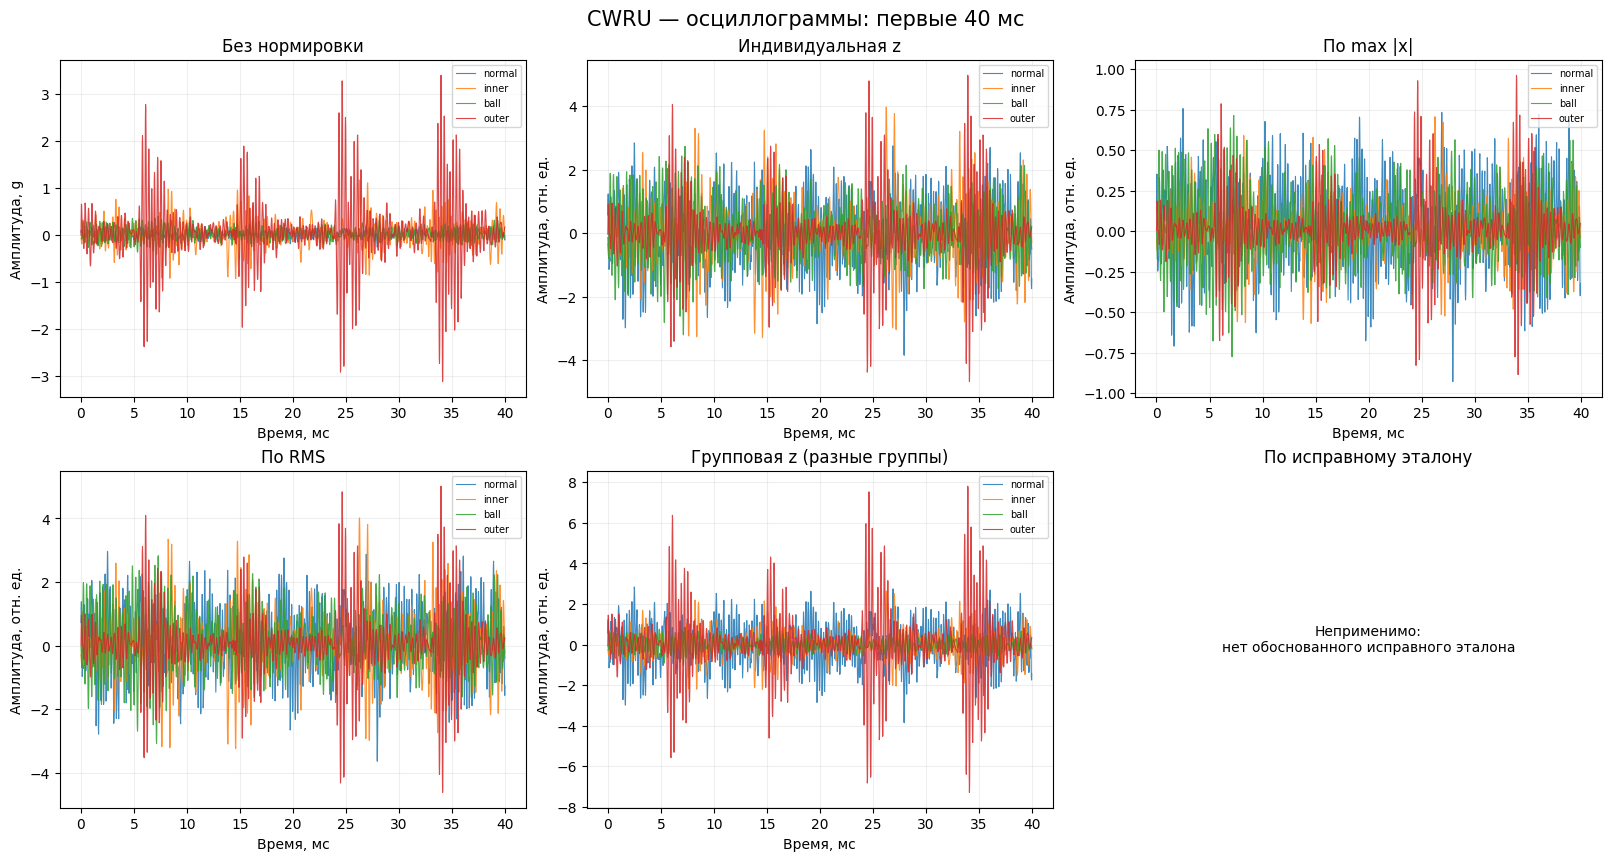

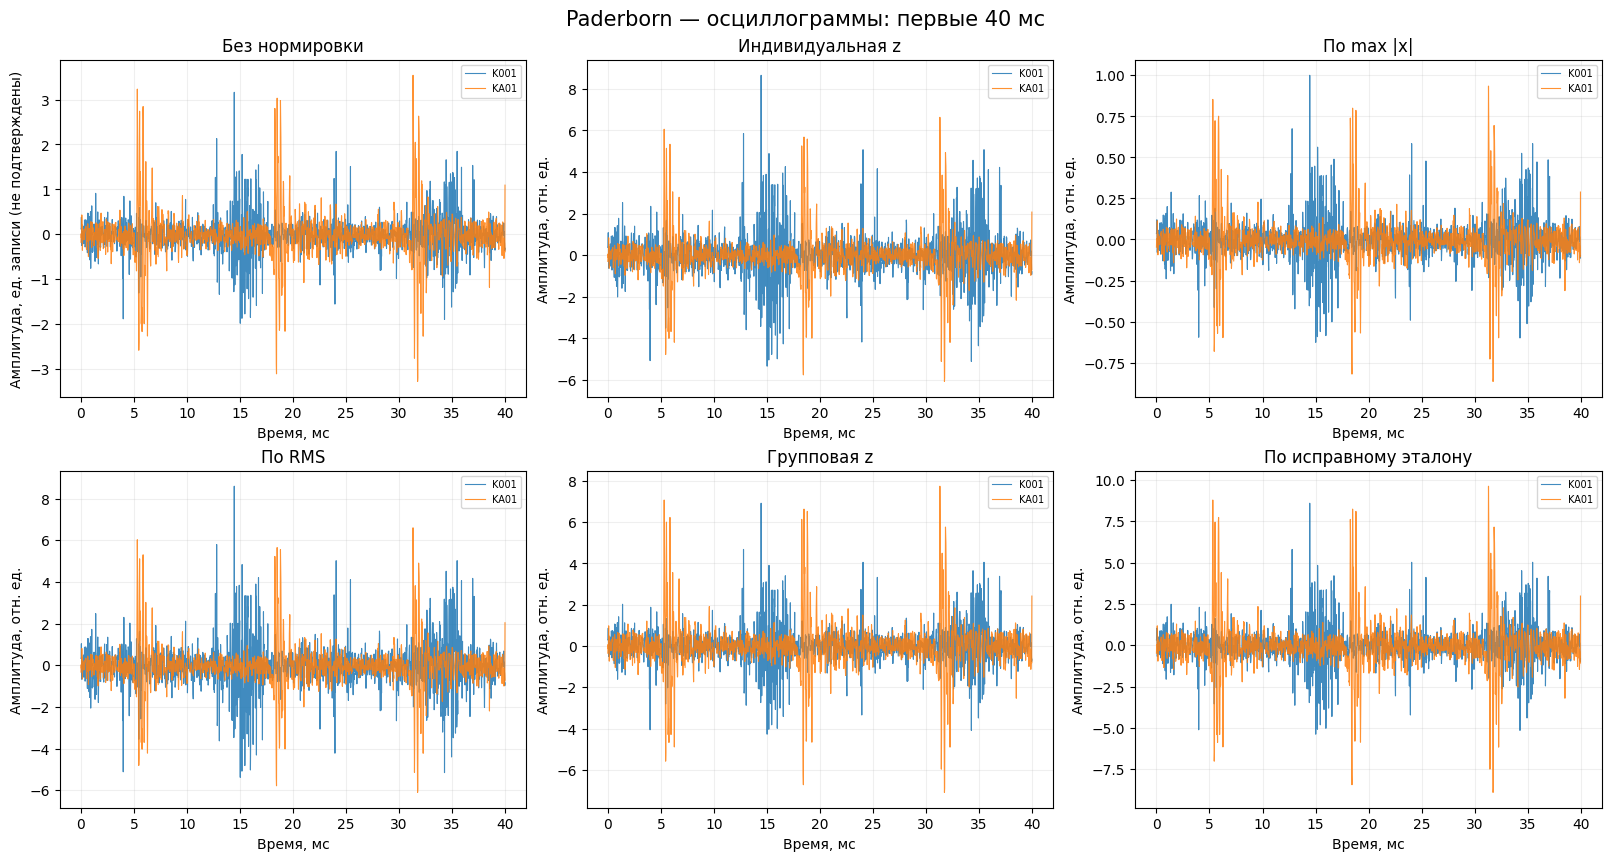

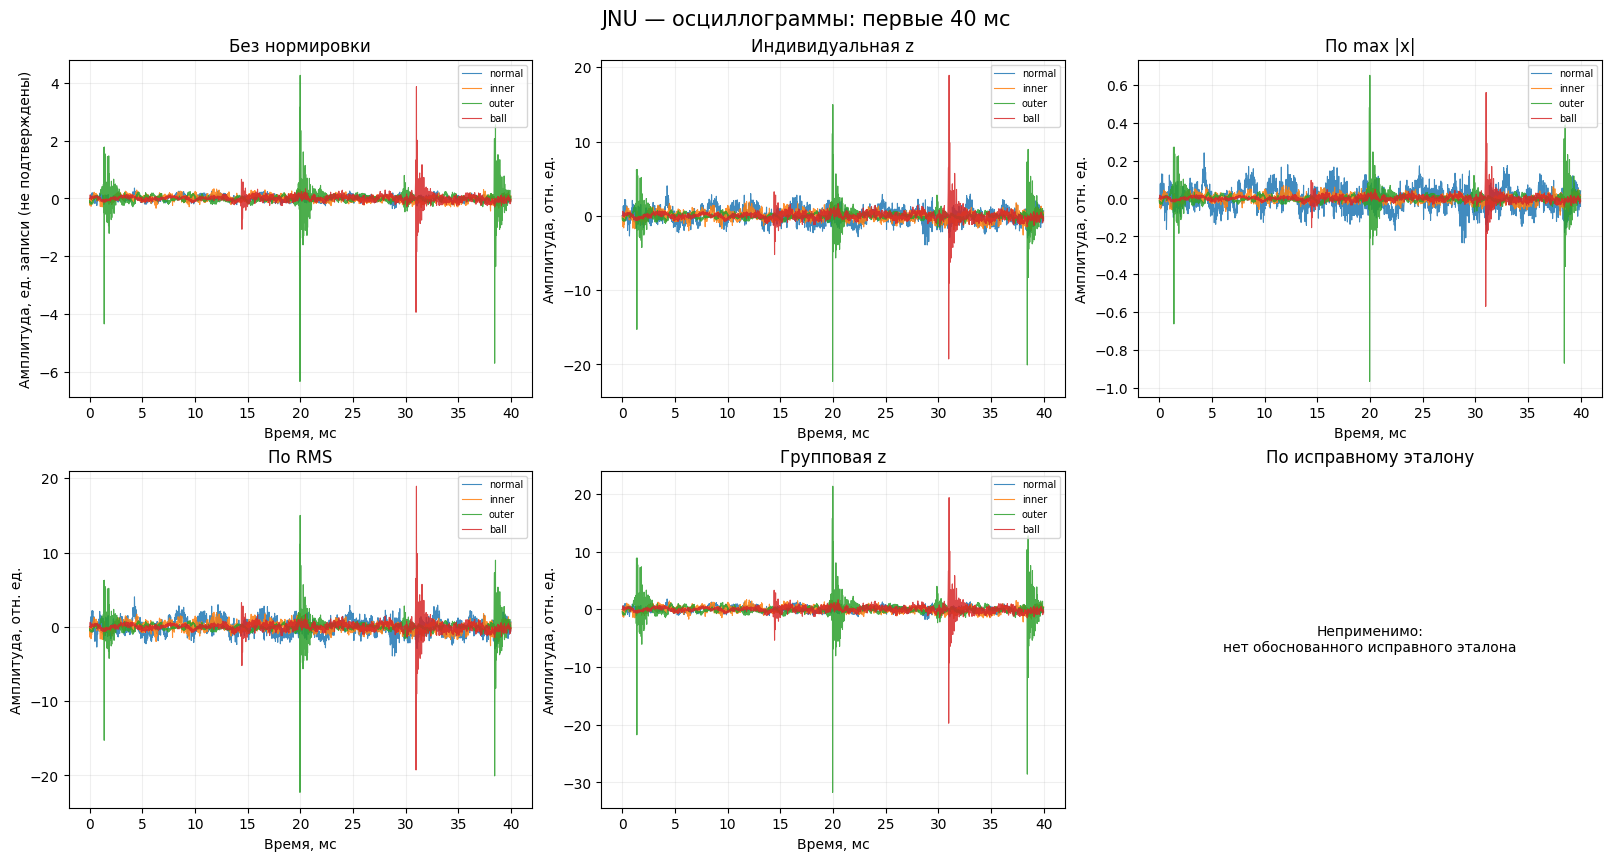

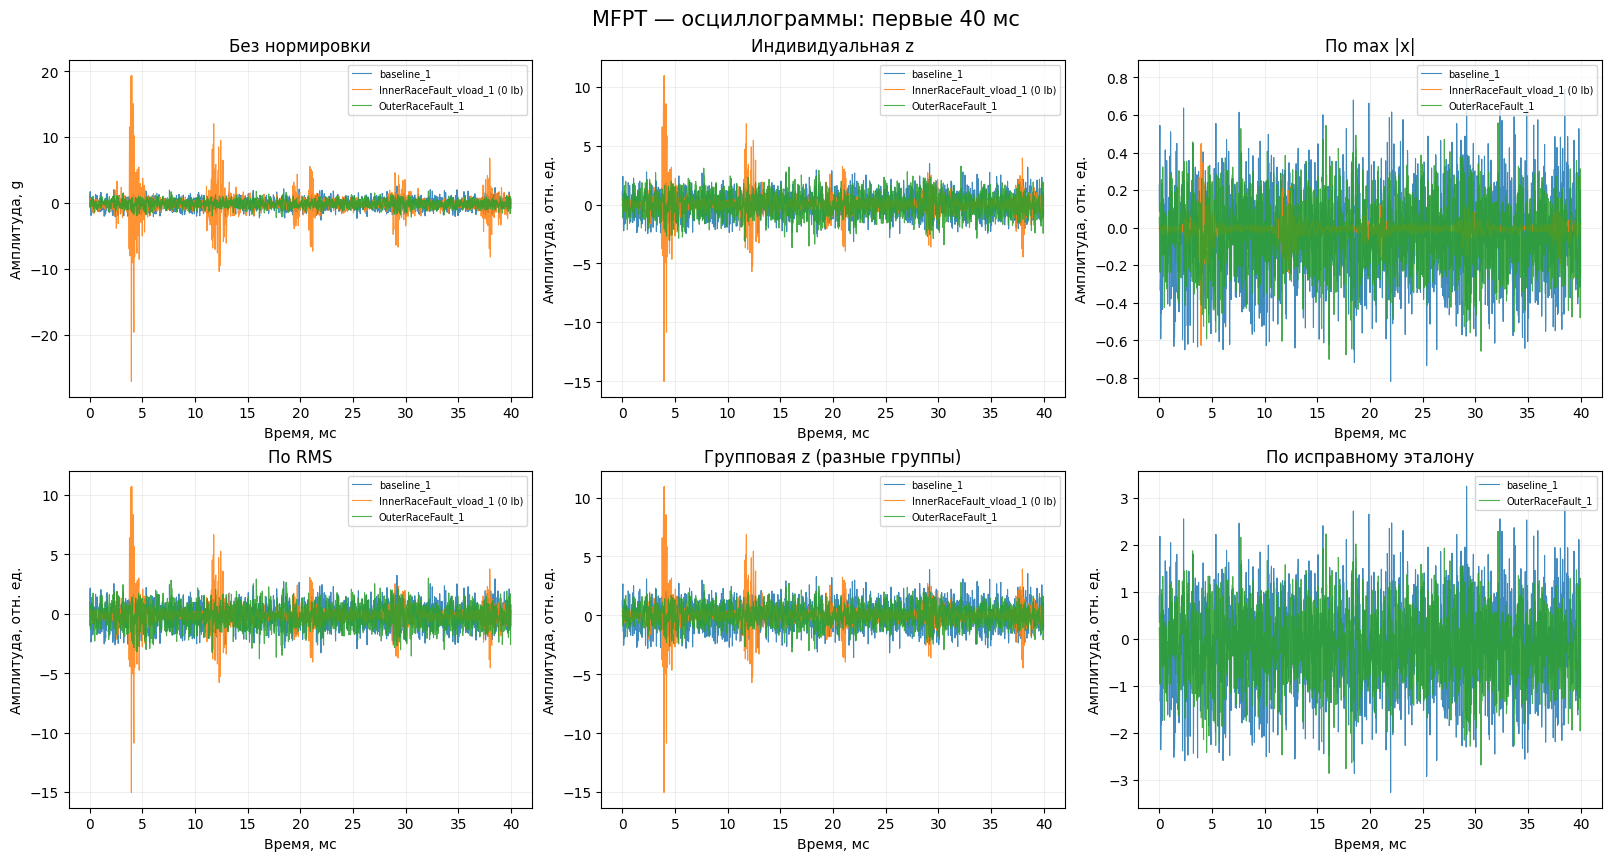

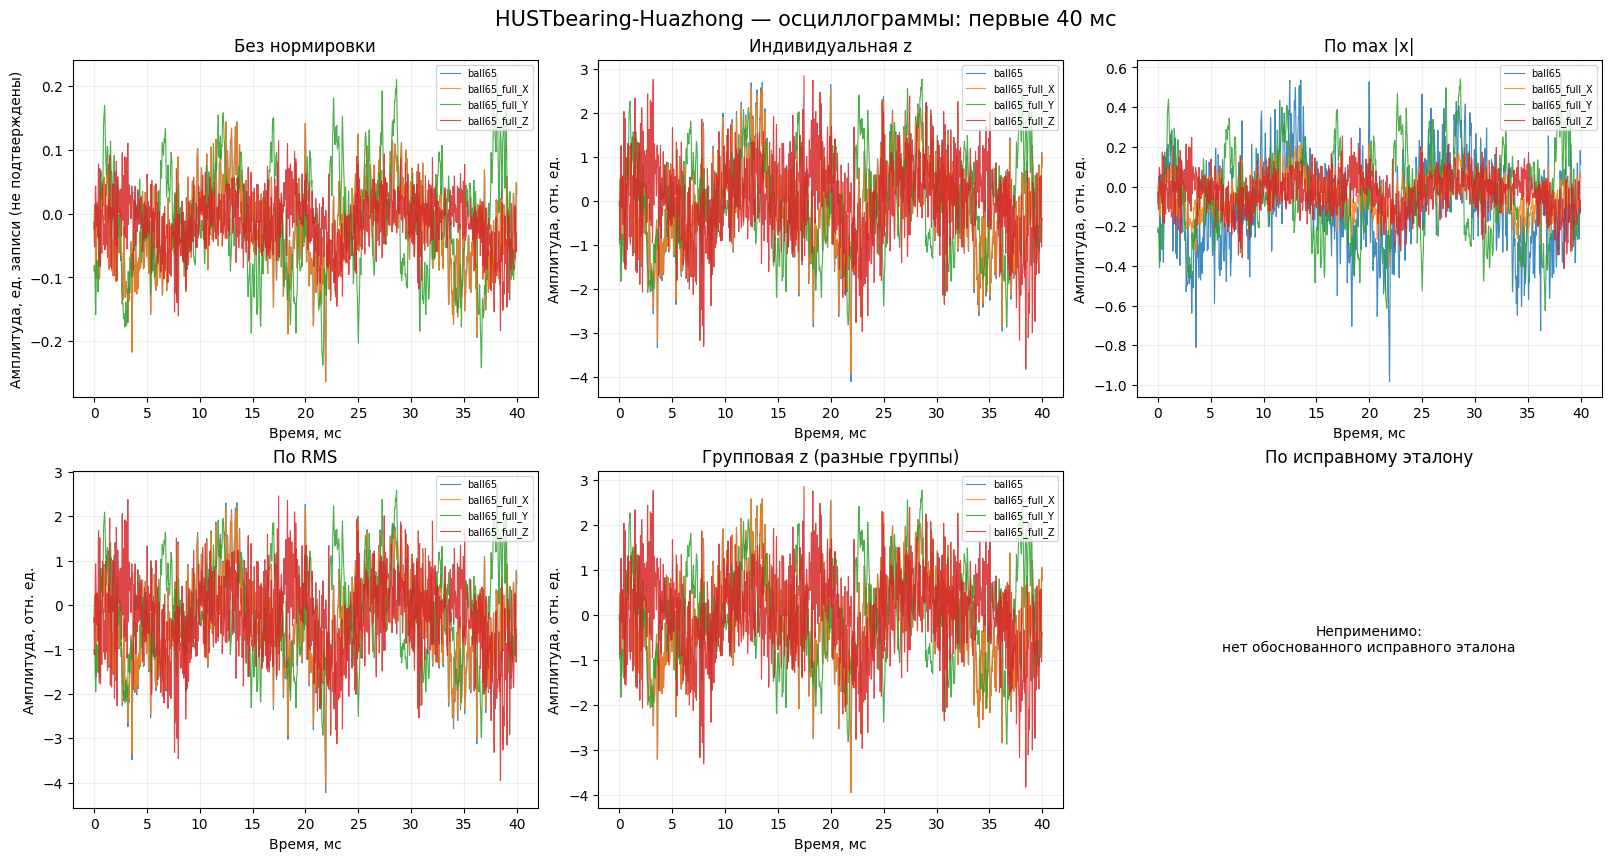

In [8]:
figure_dir = ROOT / "results/figures/normalization"
for dataset in metadata.dataset.drop_duplicates():
    fig = comparison_figure(metadata, normalized, dataset, "time", config["fs_hz"])
    save_figure(fig, figure_dir / f"{dataset}_time.png")
    plt.show()
    plt.close(fig)

### Основная пара MFPT отдельно

Запись inner при другой нагрузке имеет крупные пики и может визуально скрыть baseline/outer. Поэтому ниже отдельно показана сопоставимая пара при 270 lb: временные сигналы, распределения и спектры. Все шкалы внутри панели общие. Никакие дополнительные фильтры не применяются.

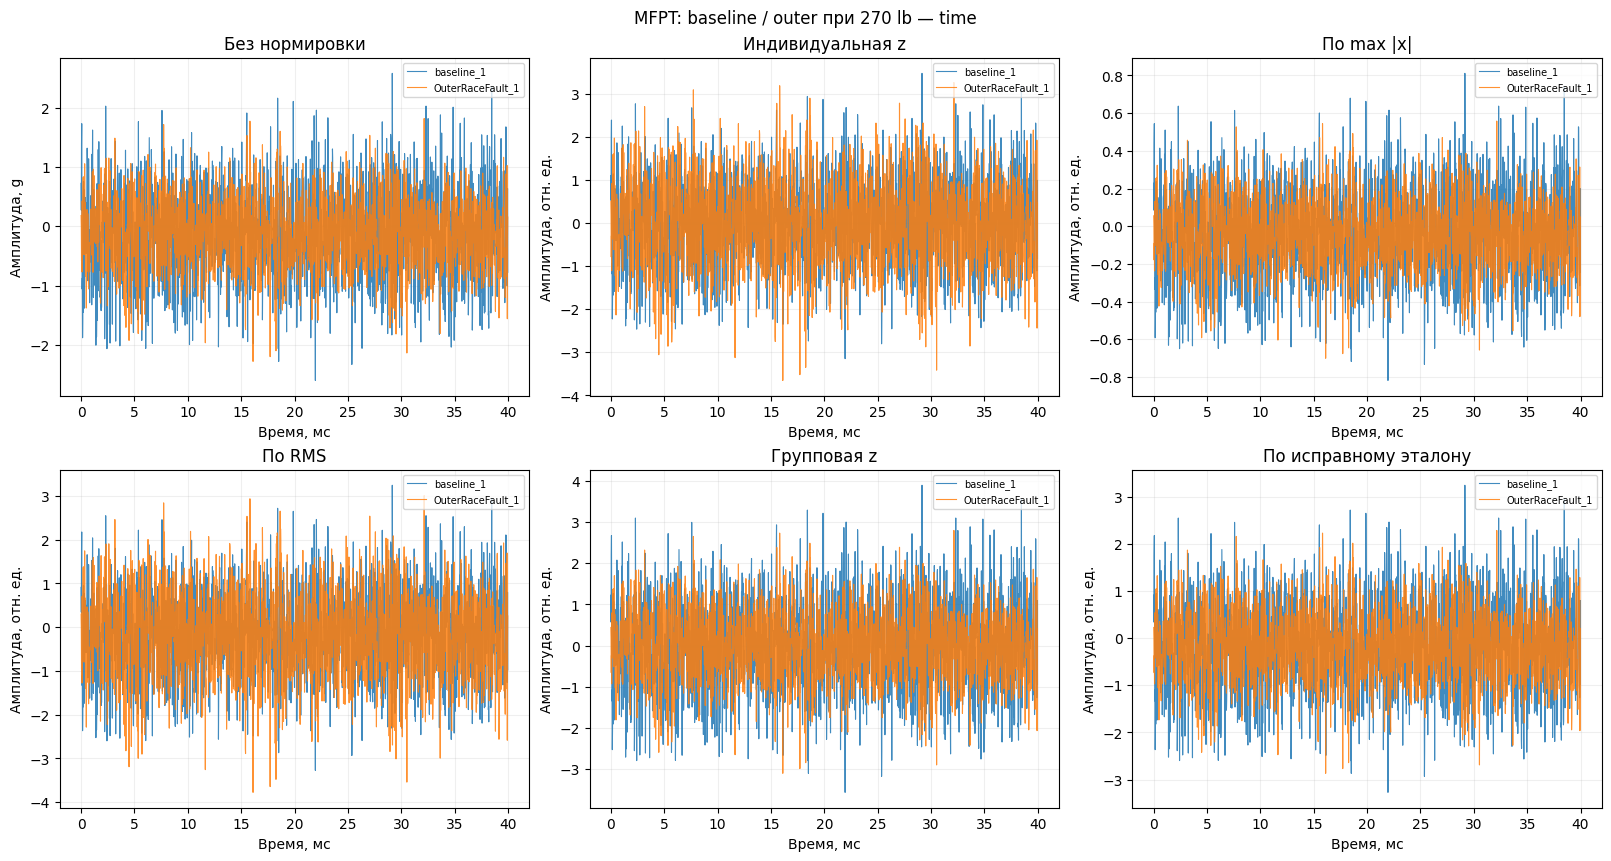

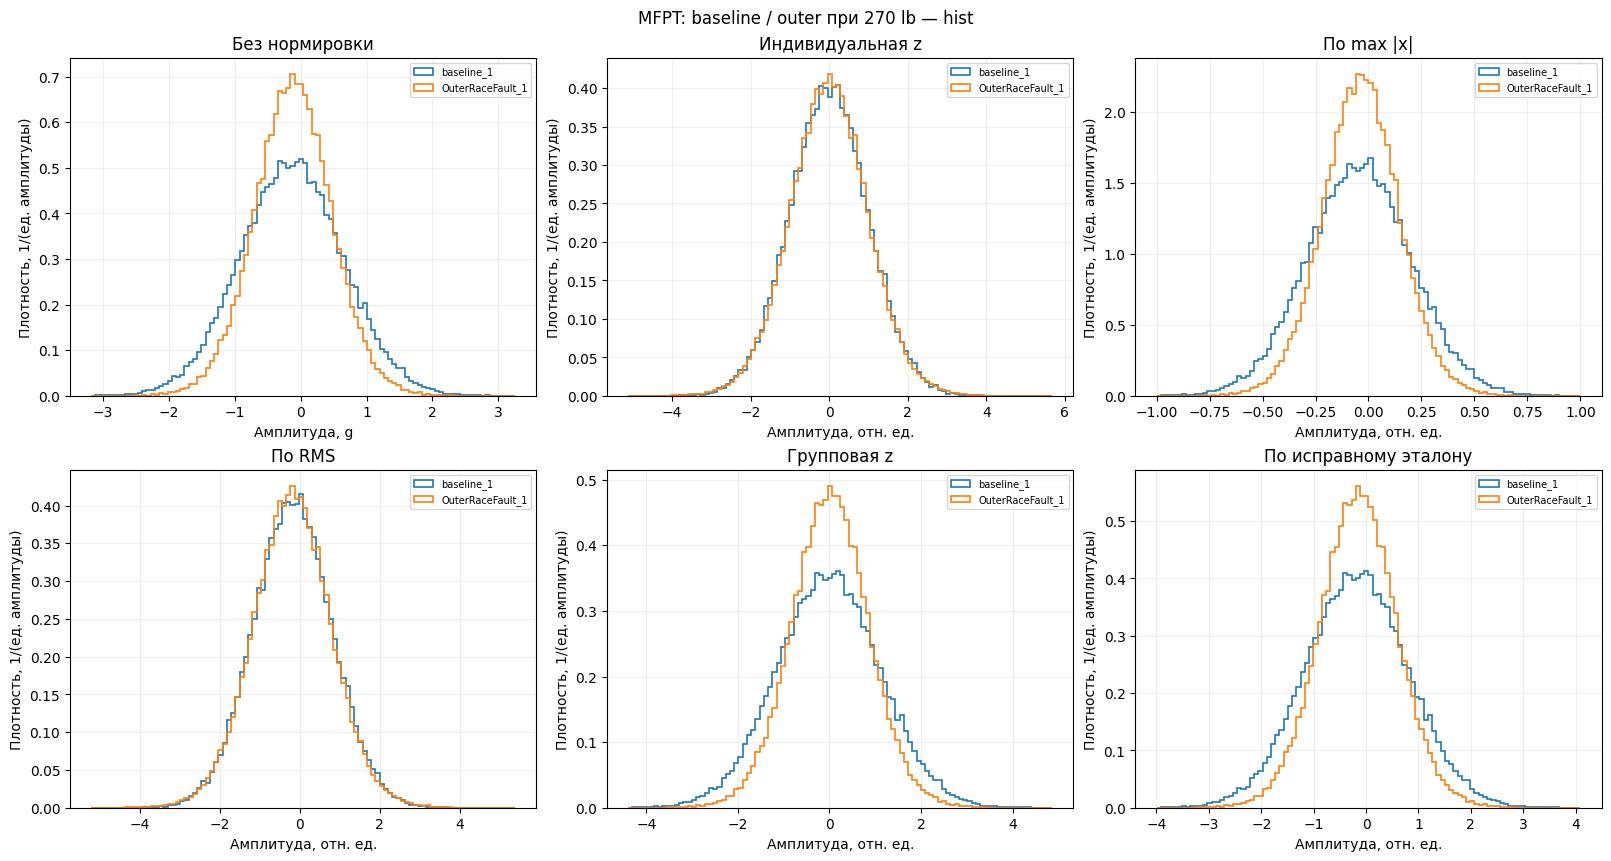

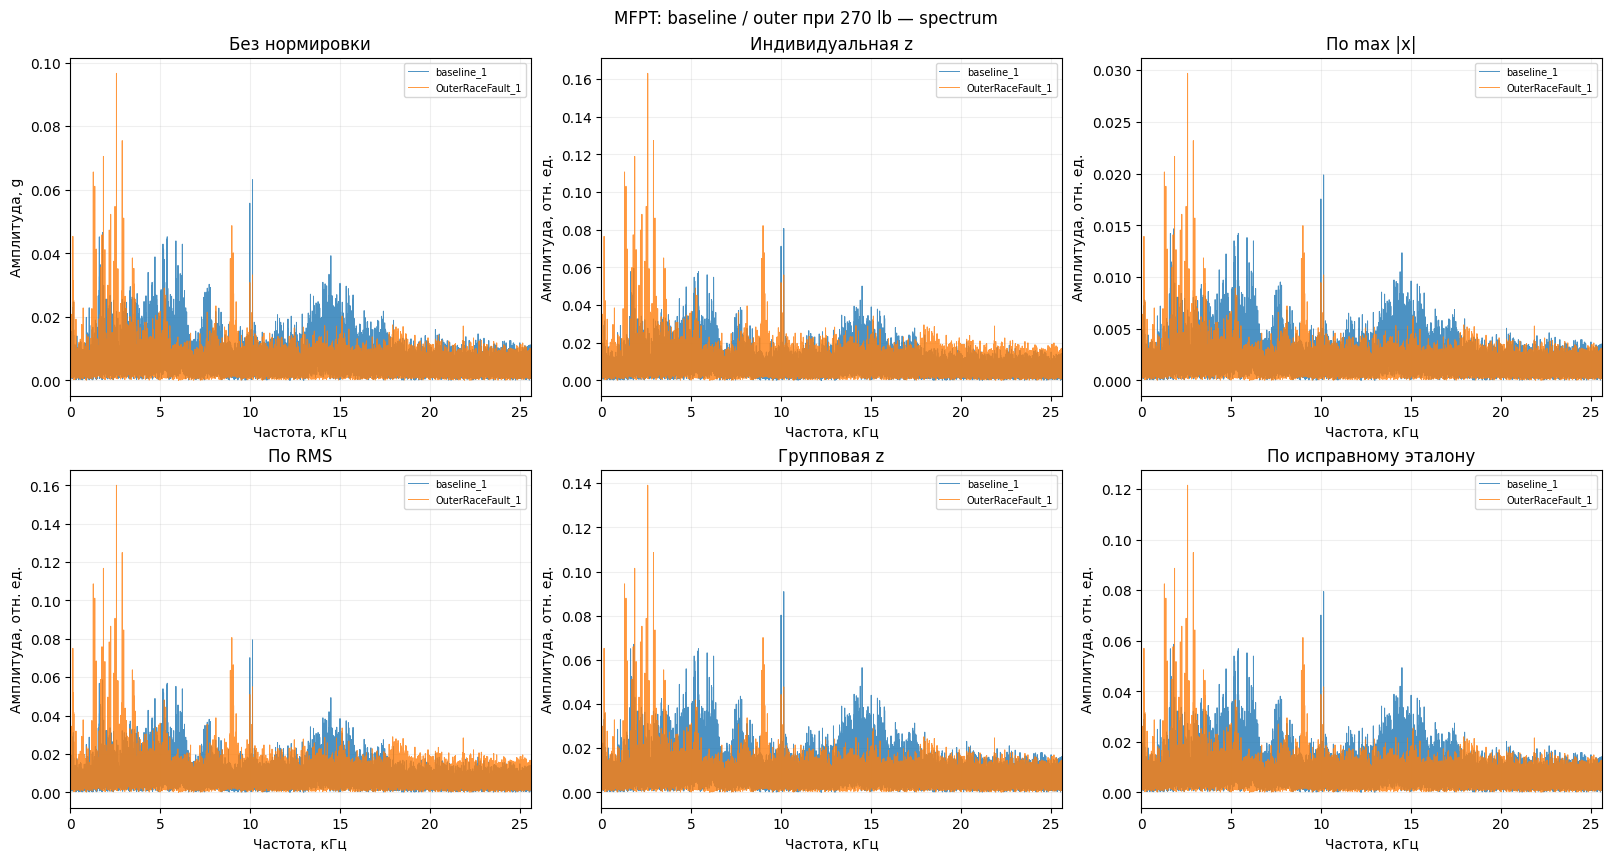

In [9]:
matched = metadata[metadata.id.isin(["mfpt_baseline_1", "mfpt_OuterRaceFault_1"])]
for kind in ("time", "hist", "spectrum"):
    fig = comparison_figure(matched, normalized, "MFPT", kind, config["fs_hz"])
    fig.suptitle("MFPT: baseline / outer при 270 lb — " + kind)
    save_figure(fig, figure_dir / f"MFPT_matched_{kind}.png")
    plt.show()
    plt.close(fig)

## 9. Распределения амплитуд

В каждой панели используются общие границы интервалов гистограммы для сопоставляемых рядов. Высота — плотность: интеграл равен 1, а не число отсчётов. Это позволяет показывать ряды разной длины, но не устраняет зависимость отсчётов и не делает их независимыми экспериментами.

Для $y=(x-c)/s$ плотность меняется как $f_y(v)=s f_x(sv+c)$. Положение и ширина меняются, стандартизованная форма сохраняется. Сходство гистограмм после индивидуальной нормировки не доказывает отсутствие неисправности.

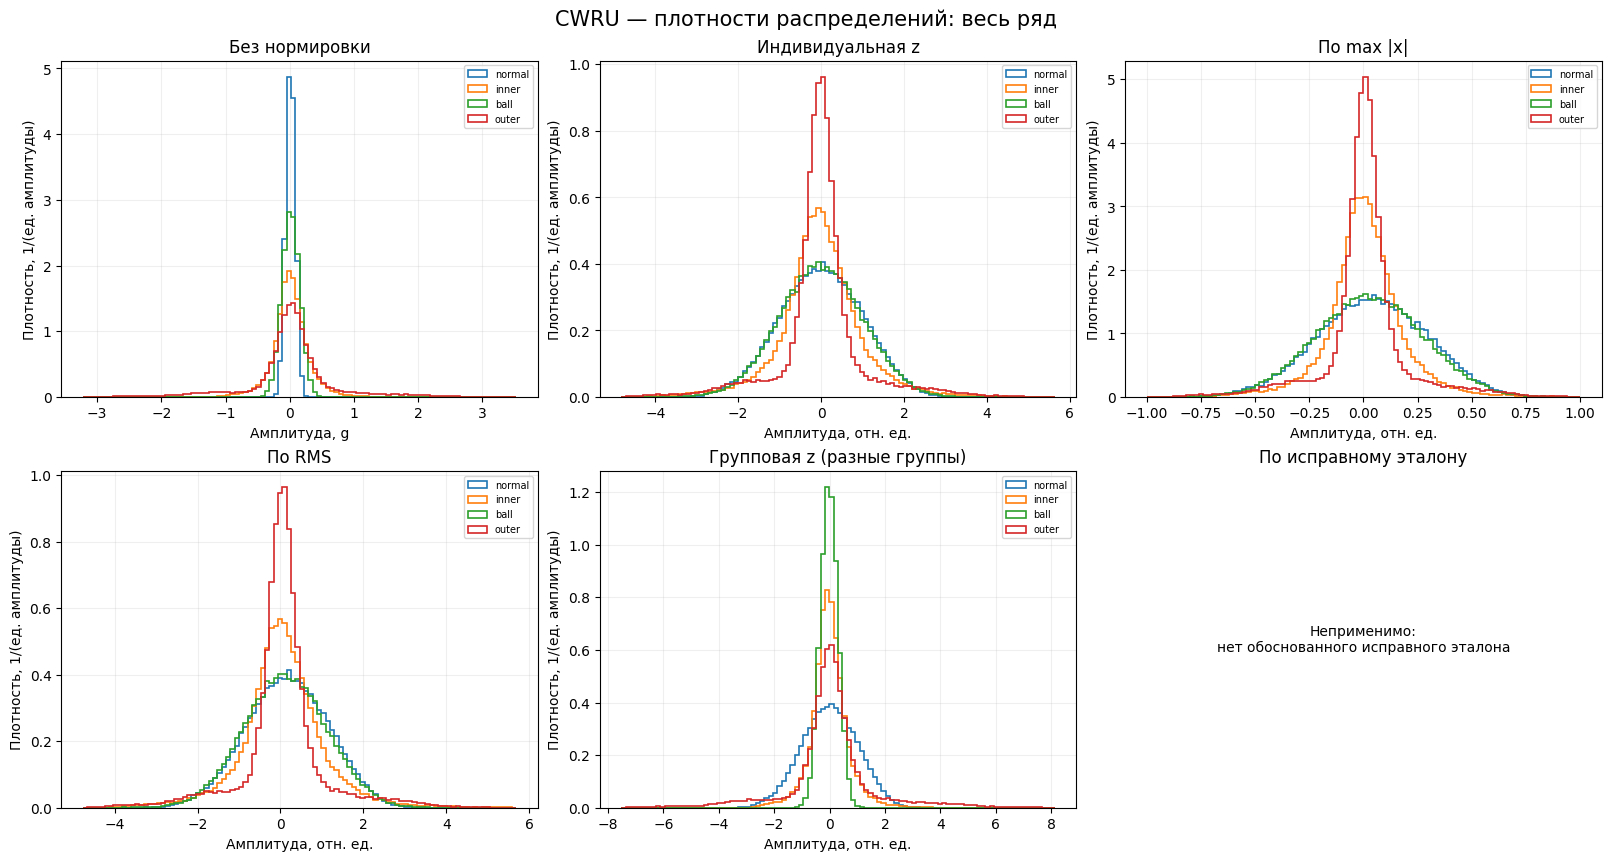

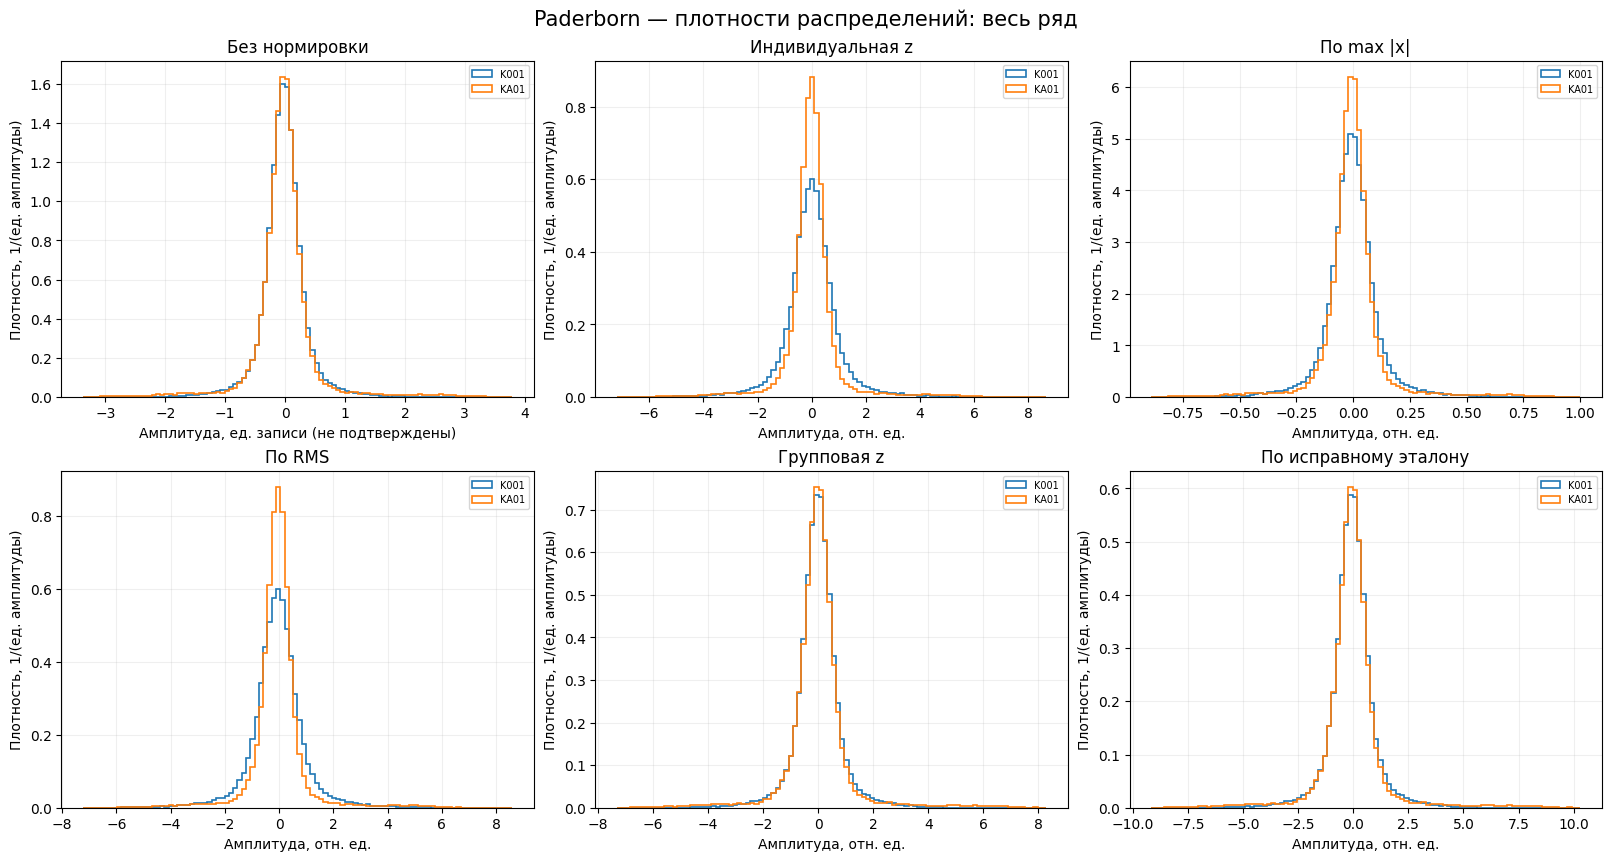

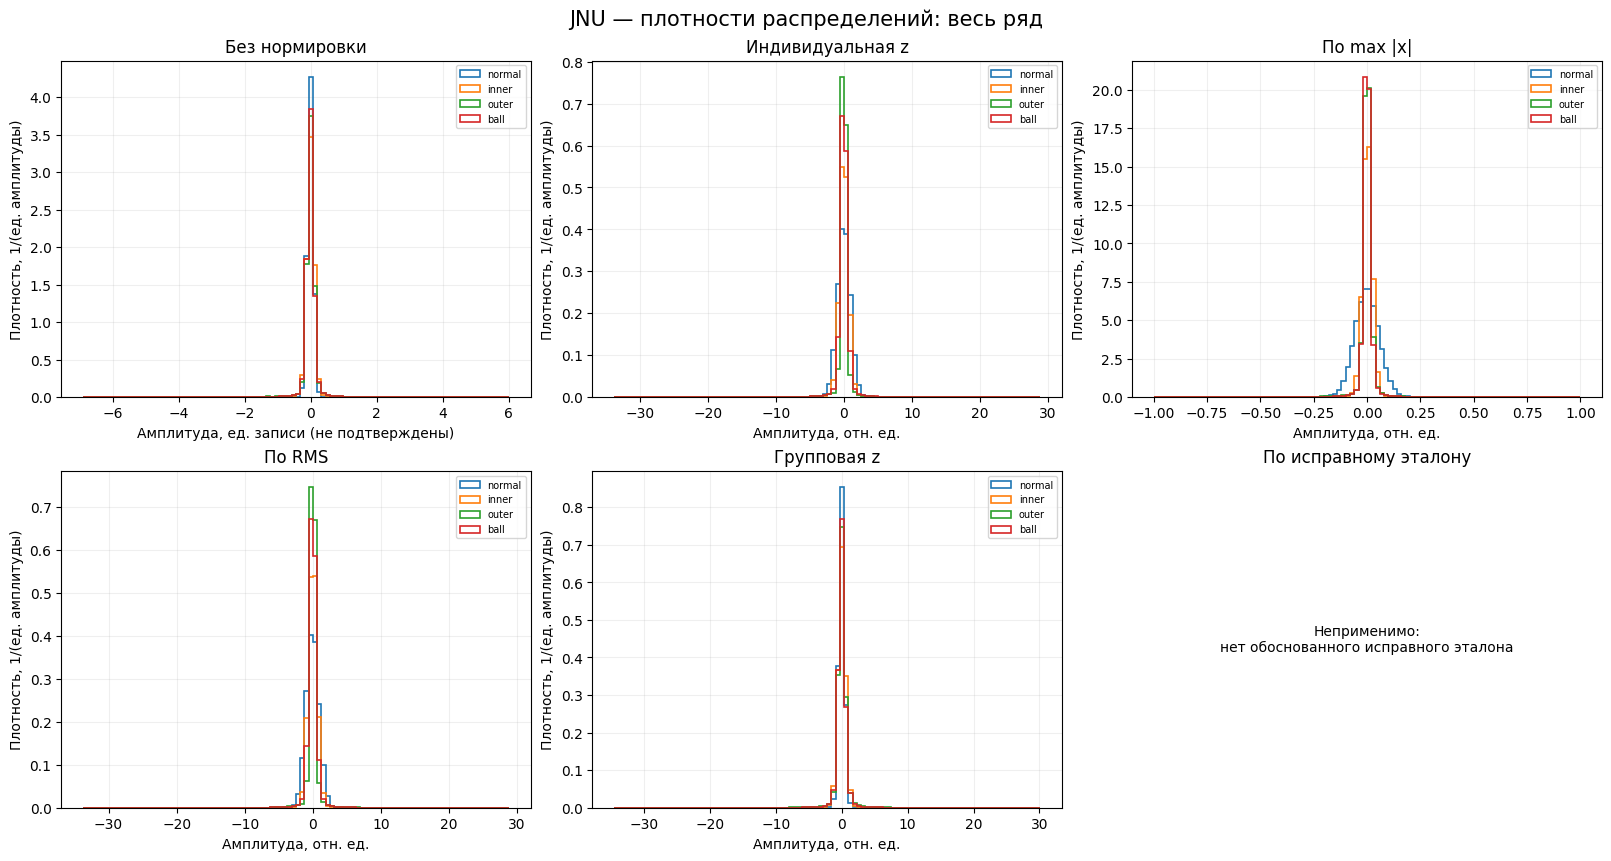

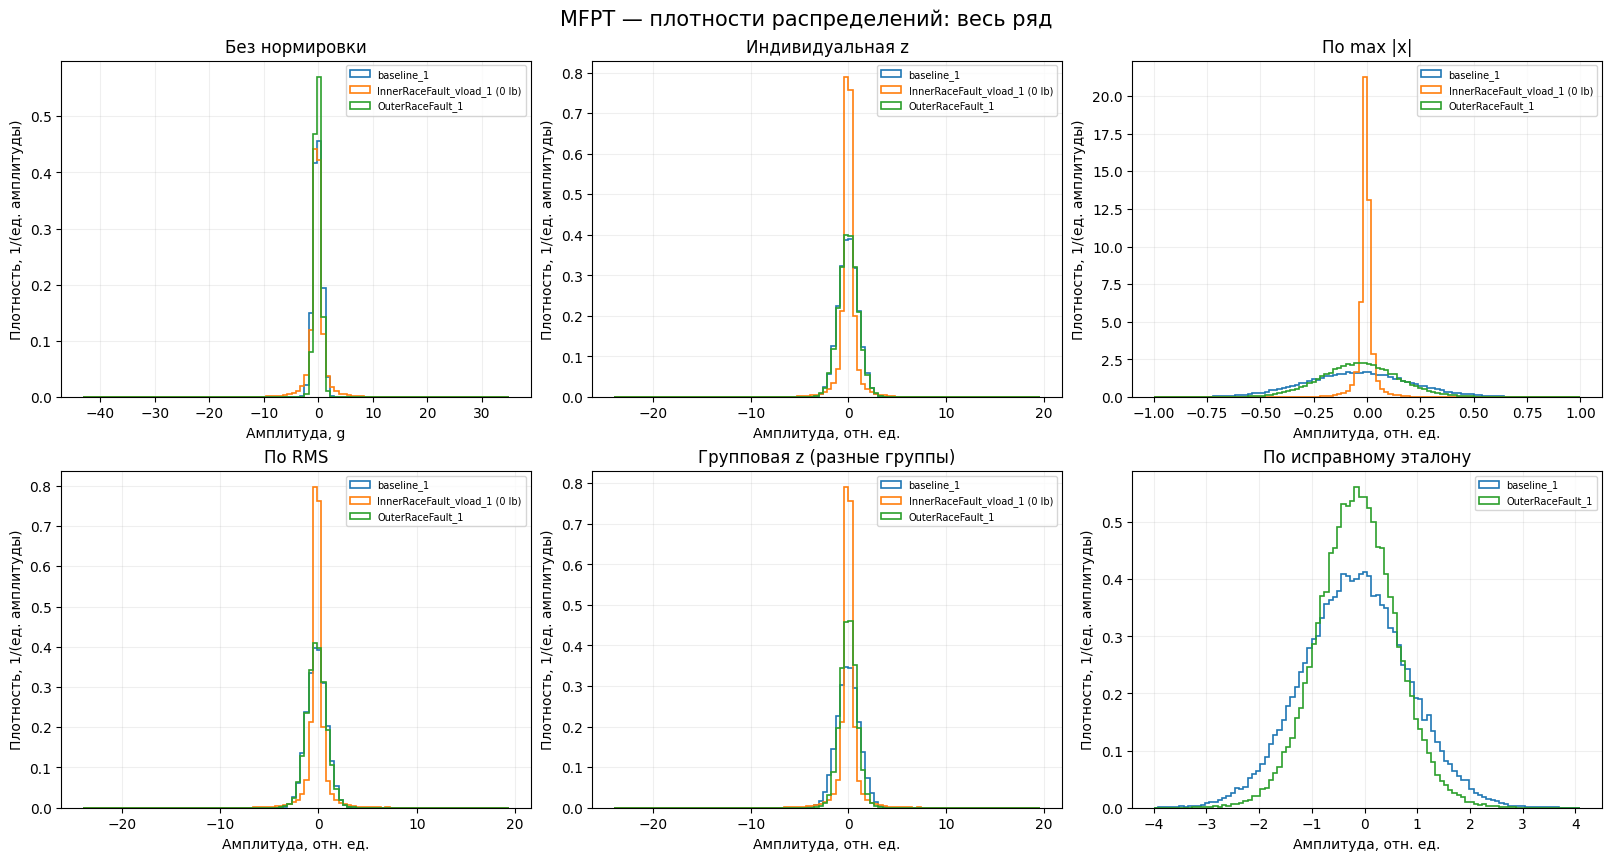

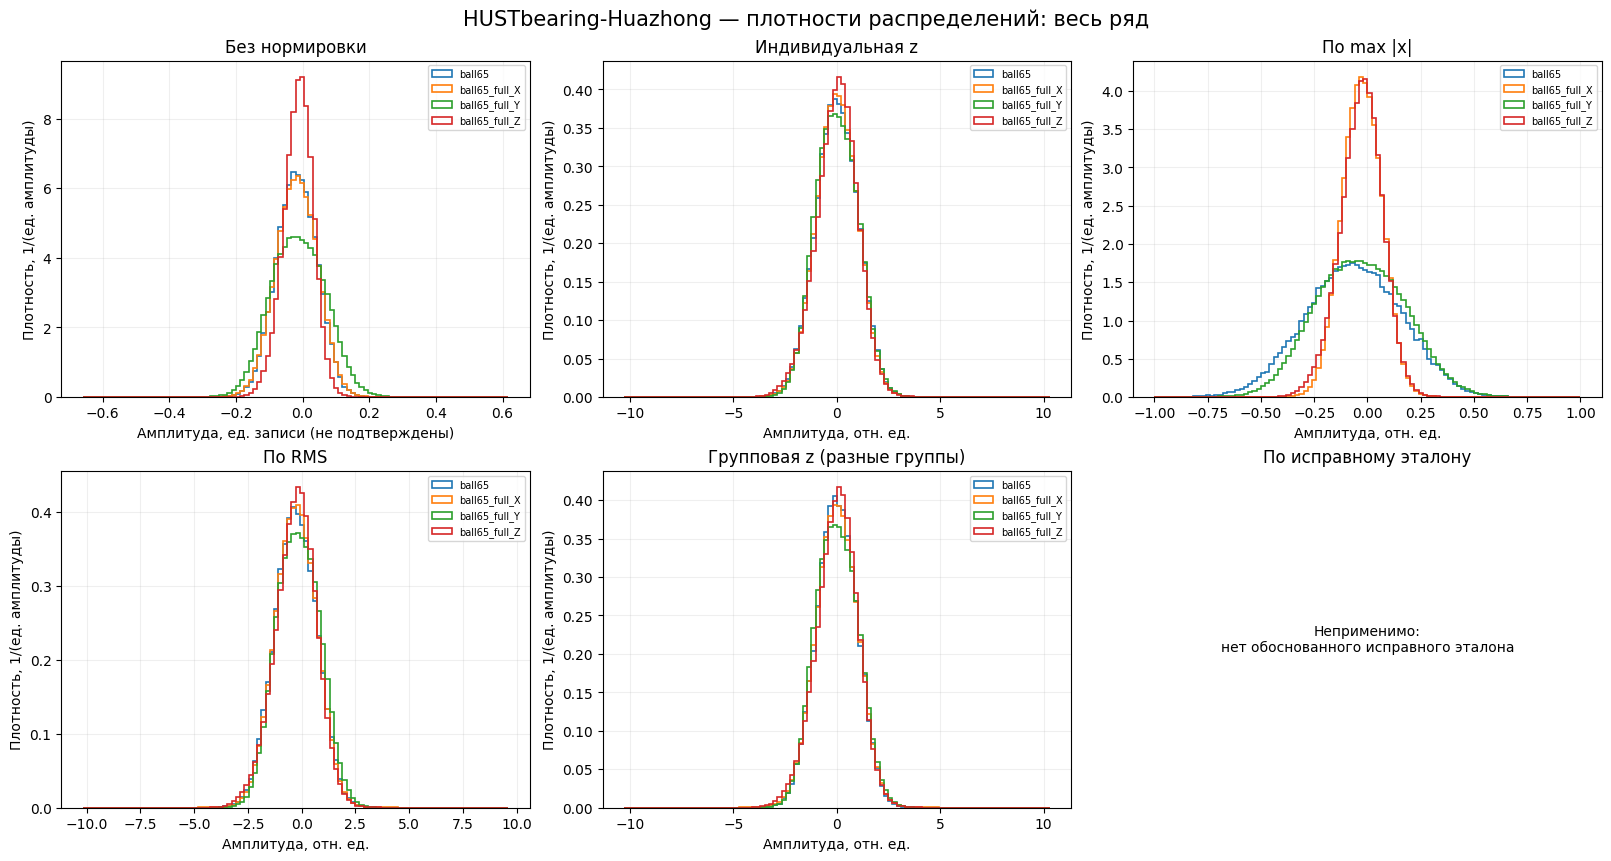

In [10]:
for dataset in metadata.dataset.drop_duplicates():
    fig = comparison_figure(metadata, normalized, dataset, "hist", config["fs_hz"])
    save_figure(fig, figure_dir / f"{dataset}_hist.png")
    plt.show()
    plt.close(fig)

## 10. Амплитудные спектры и спектральное среднее квадрата

Используем **ту же функцию амплитудного спектра**, что на этапе II: среднее удаляется только из копии для FFT; периодическое окно Ханна; деление на сумму окна; удвоение внутренних односторонних частот, но не DC и Nyquist. Частота в кГц, амплитуда в единицах соответствующего сигнала. Спектр использует весь ряд, $\Delta f=f_s/N$: 1 Гц для фрагмента и 0,09765625 Гц для полного HUST.

При $y=(x-c)/s$ центрированный амплитудный спектр равен $A_y(f)=A_x(f)/s$. Поэтому его относительная форма сохраняется. В нецентрированной FFT сдвиг меняет DC. Окно Ханна не применяется к временным сигналам при нормировке.

**Не путать с мощностью:** отдельно считаем $P_k=w_k|\mathrm{FFT}(x-\mu)/N|^2$ без окна; $w_k=2$ для парных частот, 1 для DC/Nyquist. Тогда $\sum P_k=\sigma^2$. Это среднее квадрата на частотный бин (единицы амплитуды²), не PSD и не квадрат амплитудного спектра с окном. PSD получается делением на $\Delta f$. Для ускорения это не механическая мощность в ваттах.

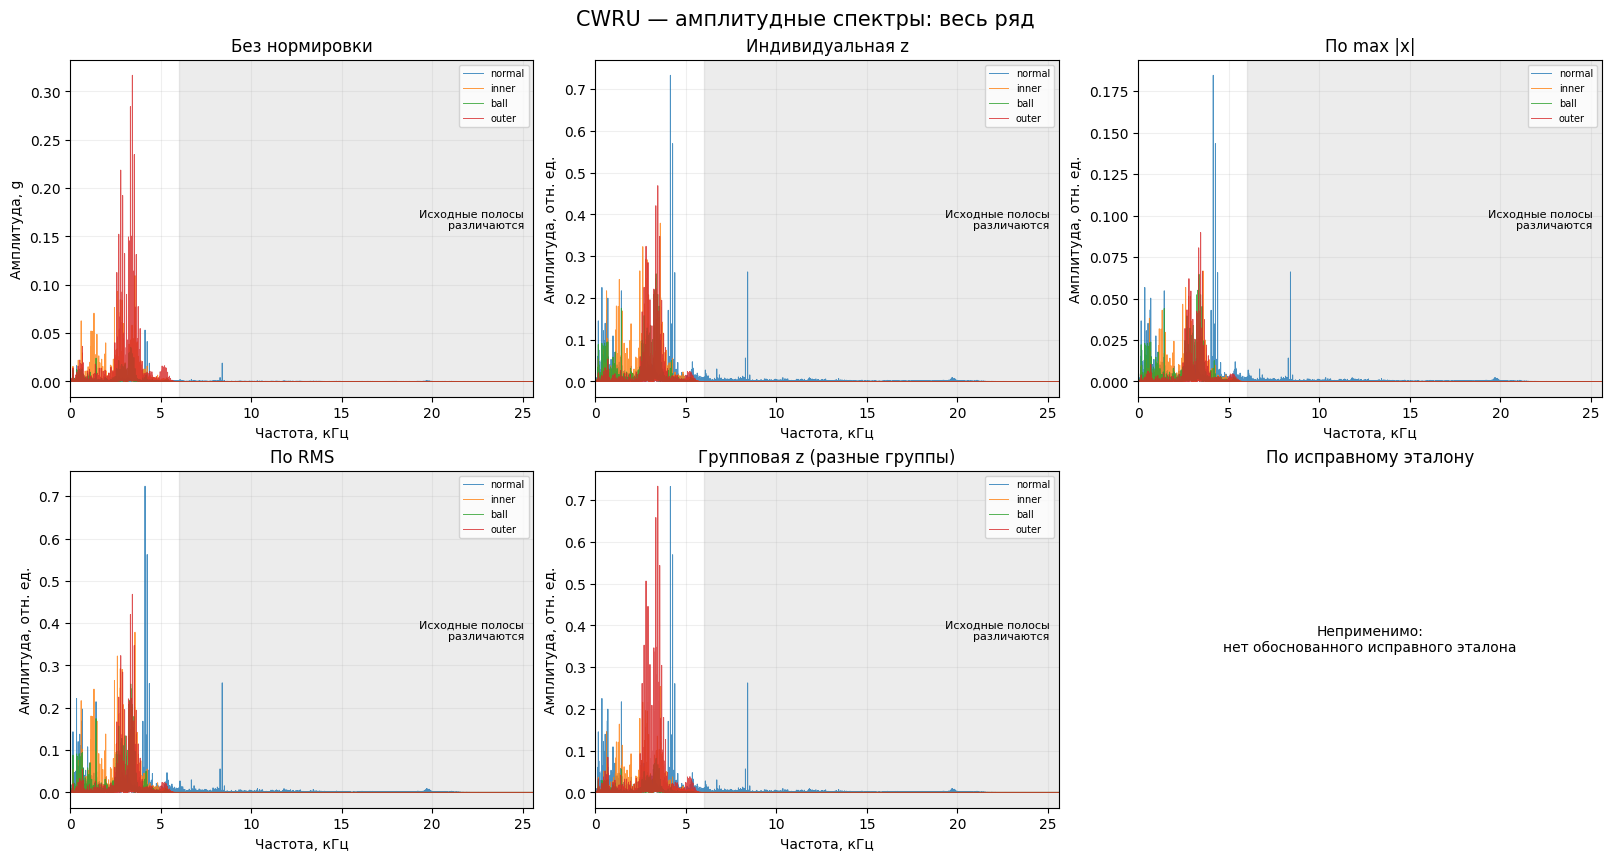

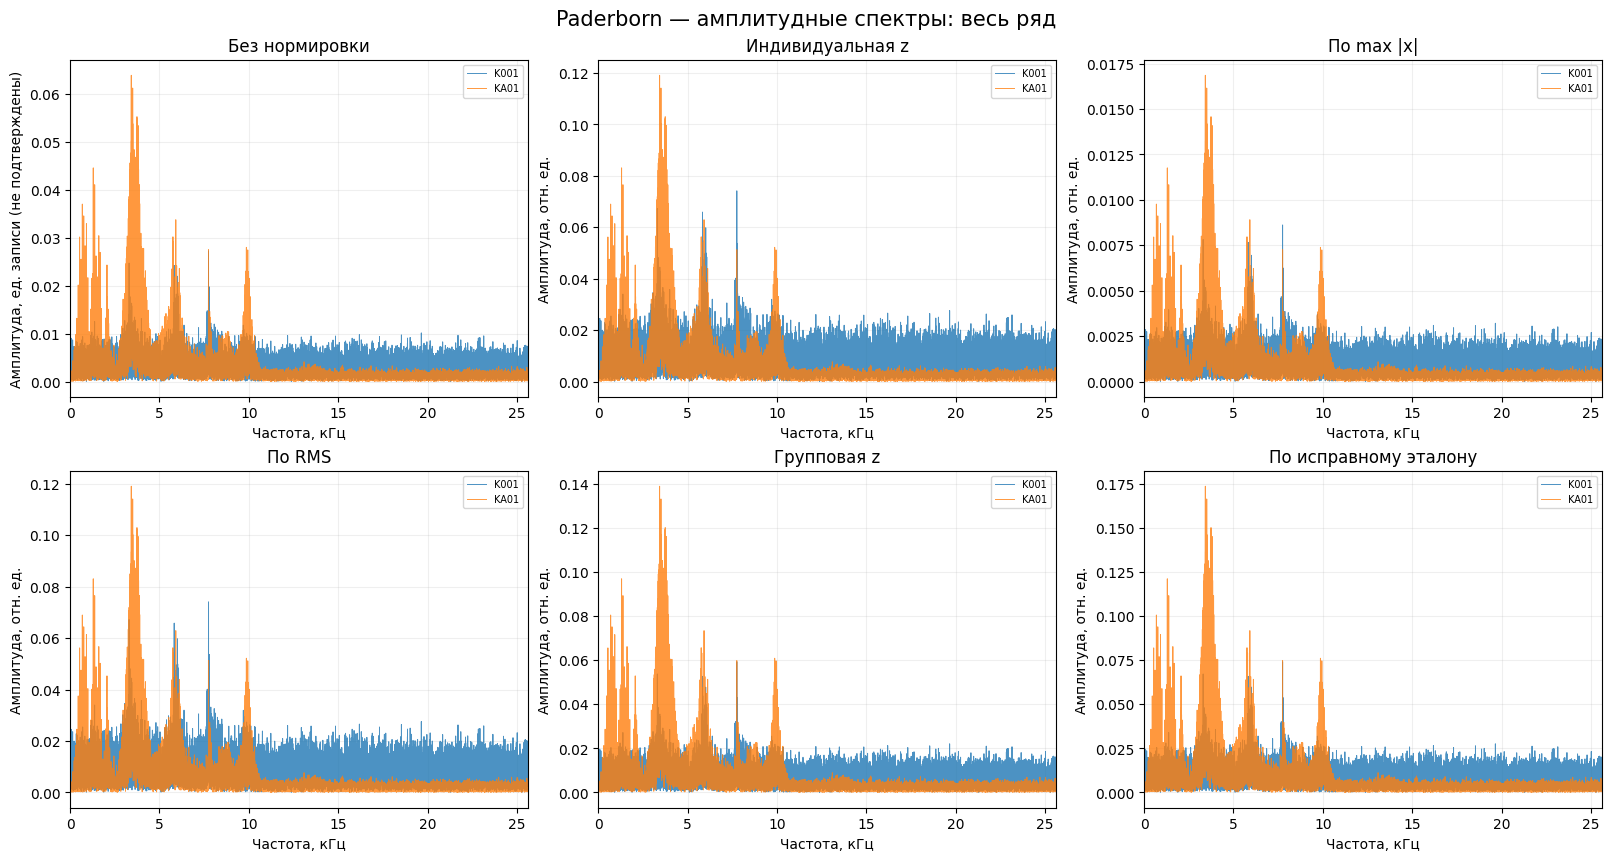

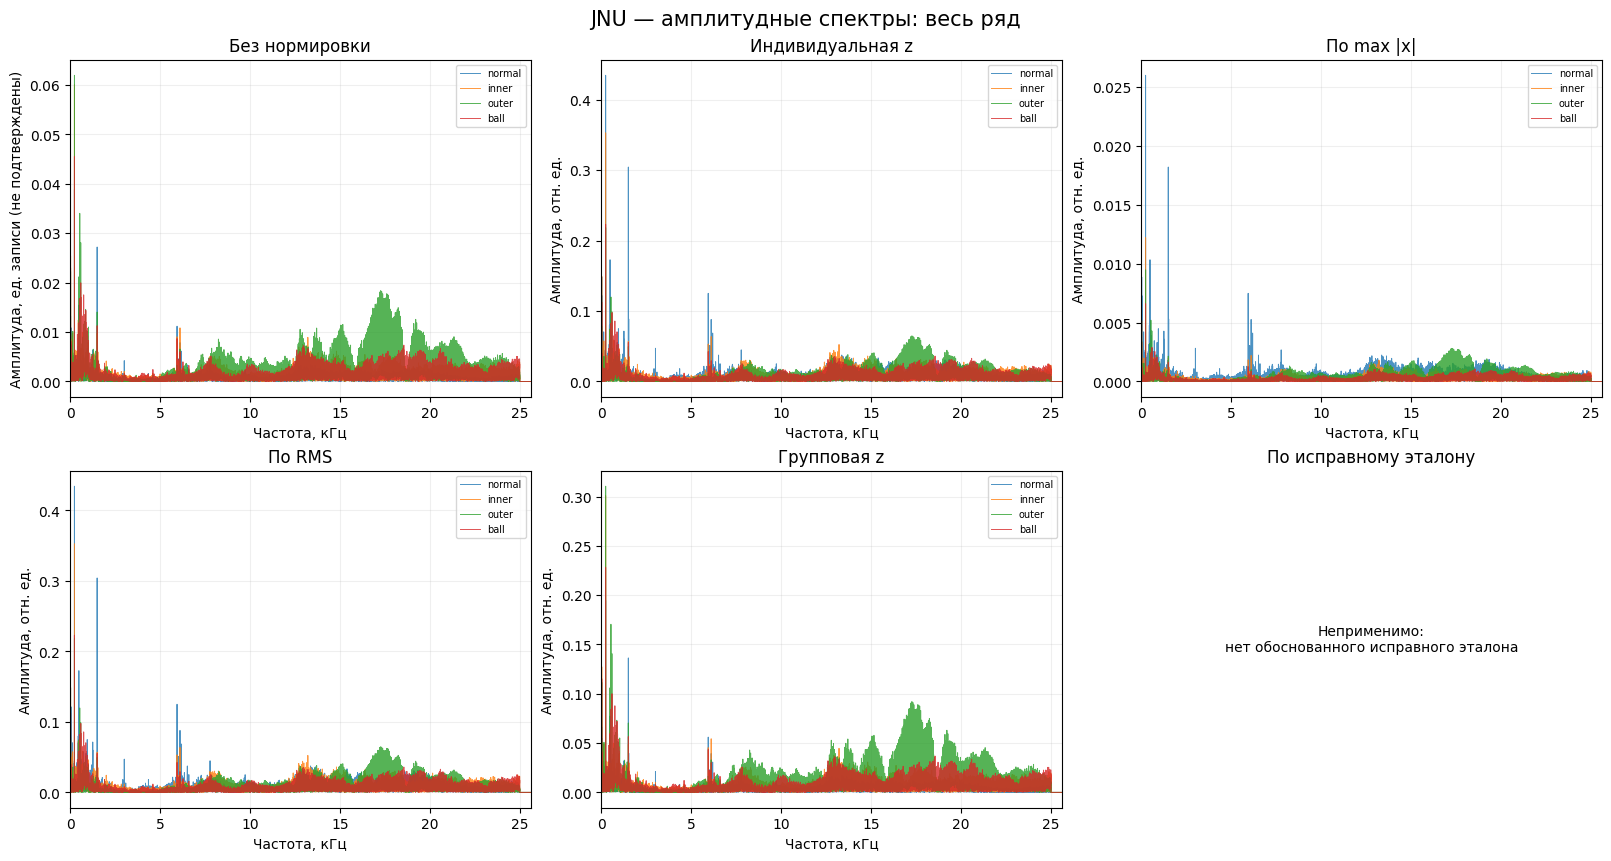

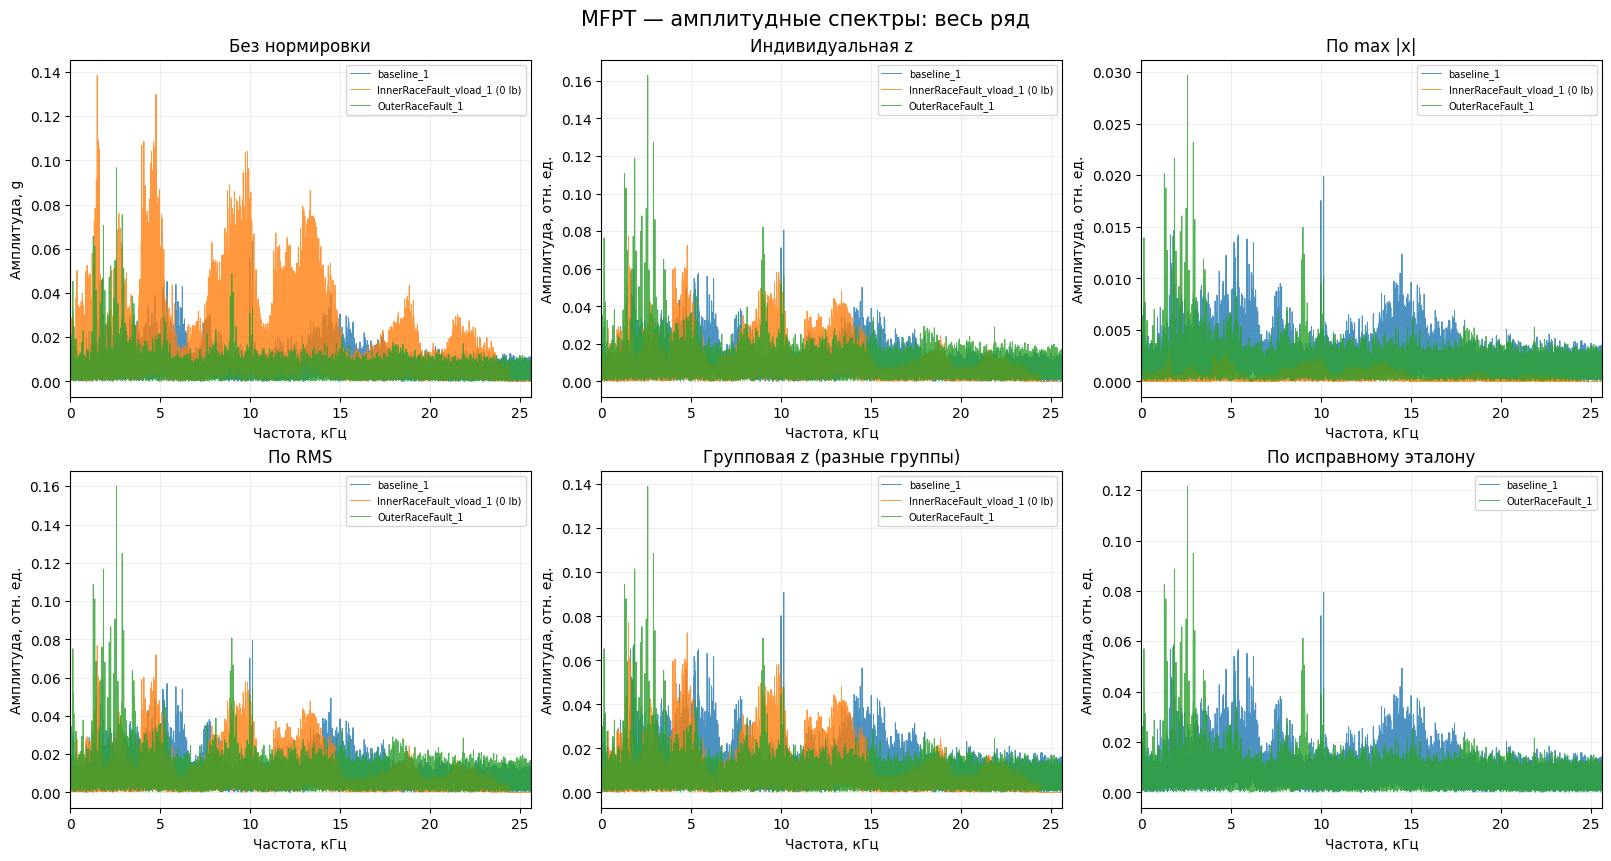

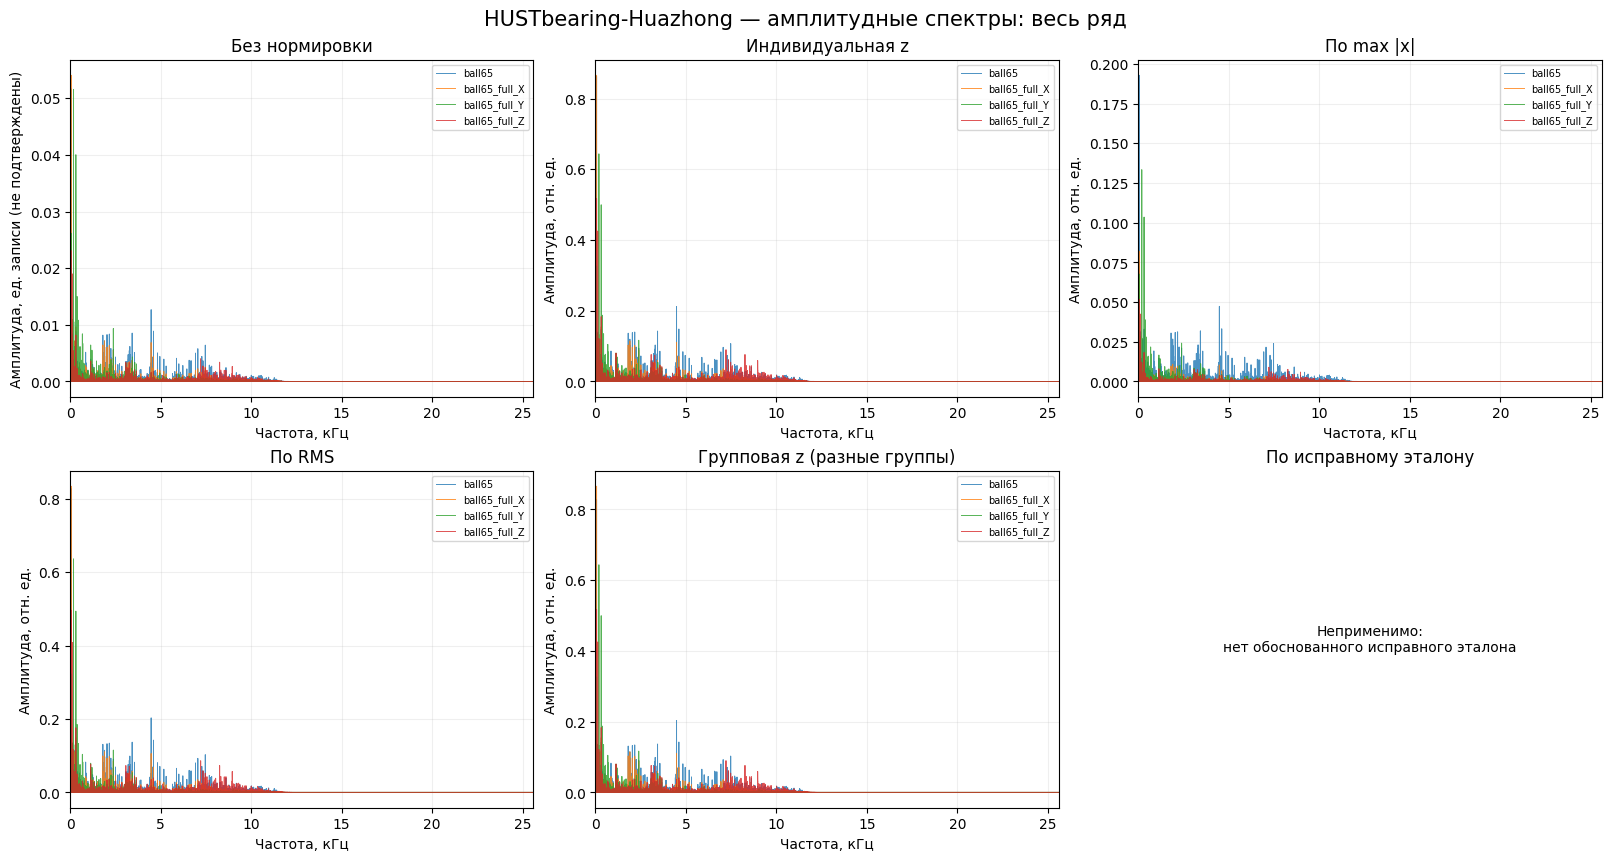

In [11]:
for dataset in metadata.dataset.drop_duplicates():
    fig = comparison_figure(metadata, normalized, dataset, "spectrum", config["fs_hz"])
    save_figure(fig, figure_dir / f"{dataset}_spectrum.png")
    plt.show()
    plt.close(fig)

ΣP до / дисперсия до: 0.3518615316805039 0.3518615316805038
ΣP после / дисперсия после: 0.5564900965948643 0.5564900965948641
Расхождение относительной формы: 3.469446951953614e-18


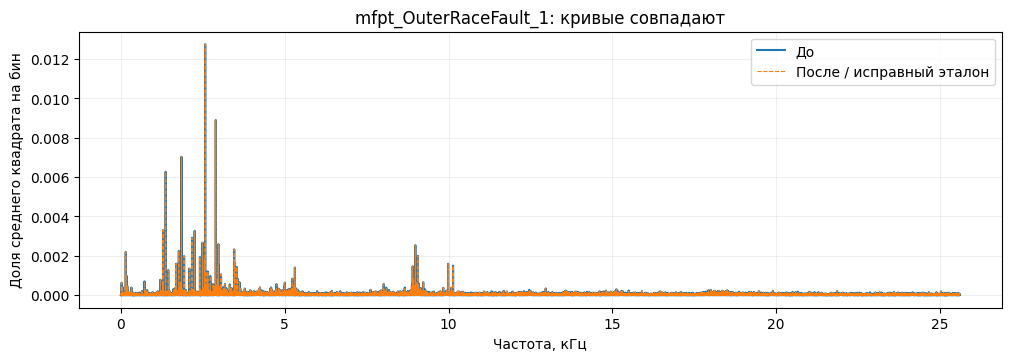

In [12]:
# Проверяем сохранение относительной спектральной формы и Parseval на реальном MFPT.
x = signals[record_id]
y = normalized[record_id, "reference_rms"]
f, px = mean_square_spectrum(x, config["fs_hz"])
_, py = mean_square_spectrum(y, config["fs_hz"])
print("ΣP до / дисперсия до:", px.sum(), np.var(x))
print("ΣP после / дисперсия после:", py.sum(), np.var(y))
print("Расхождение относительной формы:", np.max(np.abs(px/px.sum()-py/py.sum())))
fig, ax = plt.subplots(figsize=(10, 3.5), layout="constrained")
ax.plot(f/1000, px/px.sum(), label="До", linewidth=1.5)
ax.plot(f/1000, py/py.sum(), "--", label="После / исправный эталон", linewidth=.8)
ax.set(xlabel="Частота, кГц", ylabel="Доля среднего квадрата на бин", title=record_id + ": кривые совпадают")
ax.legend()
save_figure(fig, figure_dir / "MFPT_relative_power.png")
plt.show()
plt.close(fig)

## 11. Итоговая таблица всех 17 рядов

Ниже RMS для каждого метода; NA — неприменимость, а не нулевой результат. Полная длинная таблица содержит все шесть основных характеристик, центрированный пик-фактор, спектральные характеристики и происхождение каждой записи. Дополнительный спектральный центр — средняя частота с весами P_k, то есть sum(f_k P_k)/sum(P_k); он контролирует относительную форму, а не оценивает частоту дефекта. Проверки формул сохраняются в отдельной таблице. Исходные характеристики экспортируются отдельно.

In [13]:
rms_table = metrics.pivot(index="id", columns="method", values="rms_raw").reindex(columns=METHODS)
display(rms_table.round(6).fillna("NA"))
# Все характеристики для основного сопоставления MFPT.
show_columns = ["id", "method", "status", "mean", "std_centered", "rms_raw", "max_abs", "crest_raw", "crest_centered", "excess"]
display(metrics.loc[metrics.id.isin(["mfpt_baseline_1", "mfpt_OuterRaceFault_1"]), show_columns].round(6))

method,none,individual_z,max_abs,rms,group_z,reference_rms
id,,,,,,
cwru_ball,0.138266,1.0,0.252275,1.0,0.318674,NA
cwru_inner,0.289302,1.0,0.176012,1.0,0.669459,NA
cwru_normal,0.073485,1.0,0.255170,1.0,1.000000,NA
cwru_outer,0.676408,1.0,0.191787,1.0,1.565334,NA
hustbearing_medium_ball_65,0.062393,1.0,0.232900,1.0,0.959503,NA
hustbearing_medium_ball_65_full_X,0.064757,1.0,0.098126,1.0,1.000000,NA
hustbearing_medium_ball_65_full_Y,0.081010,1.0,0.209548,1.0,1.000000,NA
hustbearing_medium_ball_65_full_Z,0.046487,1.0,0.103956,1.0,1.000000,NA
jnu_ball,0.204251,1.0,0.029577,1.0,1.023400,NA


,id,method,status,mean,std_centered,rms_raw,max_abs,crest_raw,crest_centered,excess
60,mfpt_baseline_1,none,ok,-0.136671,0.783331,0.795165,3.179494,3.998535,4.212315,0.042263
61,mfpt_baseline_1,individual_z,ok,0.000000,1.000000,1.000000,4.212315,4.212315,4.212315,0.042263
62,mfpt_baseline_1,max_abs,ok,-0.042985,0.246370,0.250092,1.000000,3.998535,4.212315,0.042263
63,mfpt_baseline_1,rms,ok,-0.171877,0.985118,1.000000,3.998535,3.998535,4.212315,0.042263
64,mfpt_baseline_1,group_z,ok,-0.016390,1.127283,1.127402,4.732081,4.197332,4.212315,0.042263
65,mfpt_baseline_1,reference_rms,ok,-0.171877,0.985118,1.000000,3.998535,3.998535,4.212315,0.042263
72,mfpt_OuterRaceFault_1,none,ok,-0.113893,0.593179,0.604014,3.255293,5.389432,5.679880,0.309288
73,mfpt_OuterRaceFault_1,individual_z,ok,0.000000,1.000000,1.000000,5.679880,5.679880,5.679880,0.309288
74,mfpt_OuterRaceFault_1,max_abs,ok,-0.034987,0.182220,0.185548,1.000000,5.389432,5.679880,0.309288
75,mfpt_OuterRaceFault_1,rms,ok,-0.188560,0.982062,1.000000,5.389432,5.389432,5.679880,0.309288


## 12. Исправные и неисправные состояния

Рассчитаем отношения RMS, СКО и максимумов неисправной записи к исправной. Эти отношения описывают только доступные ряды. Для CWRU и MFPT inner у каждой строки есть предупреждение о несогласованности условий; их нельзя интерпретировать как изолированный эффект дефекта.

После индивидуальной RMS-нормировки отношение RMS становится 1 математически. После индивидуальной z оба RMS тоже равны 1. После max-нормировки RMS=1/пик-фактор, поэтому различия могут остаться. Общий положительный масштаб сохраняет исходные отношения RMS/СКО/максимумов; общий сдвиг в z сохраняет отношения СКО, но не обязан сохранять отношения RMS и максимумов.

In [14]:
comparisons = compare_states(metrics)
display(comparisons.loc[comparisons.dataset.isin(["MFPT", "Paderborn", "JNU"]),
    ["dataset", "fault_id", "method", "rms_raw_fault_over_healthy", "std_centered_fault_over_healthy", "max_abs_fault_over_healthy", "limitation"]].round(6))
# Ограничения CWRU не скрыты в общей таблице.
display(comparisons.loc[comparisons.dataset.eq("CWRU"),
    ["fault_id", "method", "rms_raw_fault_over_healthy", "shared_parameters", "limitation"]].round(6))

,dataset,fault_id,method,rms_raw_fault_over_healthy,std_centered_fault_over_healthy,max_abs_fault_over_healthy,limitation
18,Paderborn,pu_KA01,none,1.458672,1.459737,1.198480,unconfirmed_units
19,Paderborn,pu_KA01,individual_z,1.000000,1.000000,0.819988,unconfirmed_units
20,Paderborn,pu_KA01,max_abs,1.217102,1.217990,1.000000,unconfirmed_units
21,Paderborn,pu_KA01,rms,1.000000,1.000730,0.821624,unconfirmed_units
22,Paderborn,pu_KA01,group_z,1.459736,1.459737,1.197373,unconfirmed_units
23,Paderborn,pu_KA01,reference_rms,1.458672,1.459737,1.198480,unconfirmed_units
24,JNU,jnu_inner,none,1.903686,1.902958,3.289942,incomplete_load_and_units
25,JNU,jnu_outer,none,3.174235,3.174340,4.374551,incomplete_load_and_units
26,JNU,jnu_ball,none,2.283190,2.283395,4.613618,incomplete_load_and_units
27,JNU,jnu_inner,individual_z,1.000000,1.000000,1.729286,incomplete_load_and_units


,fault_id,method,rms_raw_fault_over_healthy,shared_parameters,limitation
0,cwru_inner,none,3.936909,False,different_native_bandwidth
1,cwru_ball,none,1.881560,False,different_native_bandwidth
2,cwru_outer,none,9.204755,False,different_native_bandwidth
3,cwru_inner,individual_z,1.000000,False,different_native_bandwidth
4,cwru_ball,individual_z,1.000000,False,different_native_bandwidth
5,cwru_outer,individual_z,1.000000,False,different_native_bandwidth
6,cwru_inner,max_abs,0.689783,False,different_native_bandwidth
7,cwru_ball,max_abs,0.988654,False,different_native_bandwidth
8,cwru_outer,max_abs,0.751605,False,different_native_bandwidth
9,cwru_inner,rms,1.000000,False,different_native_bandwidth


## 13. Сохранение параметров и применение без повторной оценки

Манифест содержит состав групп, веса, коэффициенты, исходные метаданные, SHA-256 входов, версии библиотек и причины неприменимости. Новые нормированные NPY не создаются: их можно восстановить из неизменённых входов и параметров. Общие параметры можно переносить только на согласованные единицы, канал, режим и предобработку; текущий эксперимент такого переноса на новые подшипники не проверяет.

In [15]:
manifest = write_results(ROOT, config, metadata, signals, fitted, membership,
    parameters_used, metrics, checks, comparisons)
# Читаем реально сохранённый JSON и применяем к уже загруженному массиву без fit.
saved = json.loads((ROOT / "results/manifests/normalization_manifest.json").read_text(encoding="utf-8"))
p_restored = Parameters.from_dict(saved["groups"]["reference_rms:MFPT_healthy_270lb"]["parameters"])
y_restored = apply(signals["mfpt_OuterRaceFault_1"], p_restored)
np.testing.assert_array_equal(y_restored, normalized["mfpt_OuterRaceFault_1", "reference_rms"])
print("Параметры сохранены и повторно применены без переоценки.")

Параметры сохранены и повторно применены без переоценки.


## 14. Ограничения и выводы

- Индивидуальные методы устраняют общий множитель амплитуды, а не все различия между сигналами. Они могут убрать как нежелательное усиление измерительного тракта, так и полезную информацию о тяжести вибрации.
- Общий масштаб сохраняет относительные амплитудные различия внутри обоснованной группы; общий z-сдвиг меняет абсолютные уровни относительно нуля.
- Эксцесс и центрированный пик-фактор сохраняются по теории: их равенство после преобразования не является критерием выбора лучшей нормировки.
- После нормировки на данных пяти стендов не появляется общая физическая калибровка. Неизвестные единицы, нагрузки, частотные полосы и типы повреждения остаются ограничениями.
- Общие параметры здесь описательные и могут включать неисправные записи. Будущая процедура должна оценивать их только на обучающих данных, разделённых по физическому подшипнику/эксперименту. Вложенные фрагменты нельзя разносить между обучением и проверкой.
- HUSTbearing не позволяет исследовать различия исправного и неисправного состояния. Оси X/Y/Z — один эксперимент.
- Для объективного сравнения диагностической эффективности нужны независимые повторения, физические ID, сопоставимые полосы/режимы, калибровка и исправные контроли. Сейчас нет оснований для ROC-AUC, тестов значимости или универсального победителя.

Ниже краткий отчёт с **вычисленными** отношениями и ошибками проверок. Он пересоздаётся из результатов текущего выполнения, а не содержит вручную внесённые экспериментальные числа.

In [16]:
report = report_text(metrics, checks, comparisons)
report_dir = ROOT / "reports/stage3"
report_dir.mkdir(parents=True, exist_ok=True)
(report_dir / "NORMALIZATION_REPORT.md").write_text(report, encoding="utf-8")
display(Markdown(report))

# COS1. Этап III: описательное исследование нормировки

Источник: COS1_STAGE2_COMPLETE_2026-11-14.zip. Использованы только готовые массивы этапа II при 51 200 Гц; ресемплинг не повторялся.

17 рядов × 6 методов = 102 строк: применимо 89, неприменимо 13. Теоретические проверки: 89/89.

## Определения и гарантированные свойства

$\mu=N^{-1}\sum x_i$, $\sigma^2=N^{-1}\sum(x_i-\mu)^2$, $R=\sqrt{N^{-1}\sum x_i^2}$; делитель СКО — N, без поправки Бесселя.
Пик-фактор $C=\max|x|/R$; дополнительно центрированный $C_c=\max|x-\mu|/\sigma$. Эксцесс $K=N^{-1}\sum((x_i-\mu)/\sigma)^4-3$, без поправки на смещение оценки.

Все методы имеют вид $y=(x-c)/s$, $s>0$. Тогда $\mu_y=(\mu-c)/s$, $\sigma_y=\sigma/s$, $R_y=\sqrt{\sigma^2+(\mu-c)^2}/s$ и $\max|y|=\max_i|x_i-c|/s$.
При c=0 сохраняется обычный пик-фактор; при сдвиге это не гарантируется. Центрированный пик-фактор и эксцесс инвариантны при ненулевом СКО. Для $y=ax+b$, $a\ne0$, стандартизованные отсчёты отличаются только знаком, исчезающим в четвёртой степени.

Для 6x: $\mu_{6x}=6\mu_x$, $\sigma_{6x}=6\sigma_x$, поэтому $(6x-6\mu_x)/(6\sigma_x)=(x-\mu_x)/\sigma_x$ при $\sigma_x>0$.

Методы: none; individual_z (c=μ, s=σ); max_abs (c=0, s=max|x|); rms (c=0, s=R); group_z (c=μ группы, s=σ группы); reference_rms (c=0, s=медиана RMS исправных эталонов). Нулевой знаменатель вызывает ValueError, а не подменяется epsilon. Для постоянных сигналов эксцесс и центрированный пик-фактор не определены.

## Группы и эталоны

В общей z-нормировке каждая включённая запись получает одинаковый вес: μ_D=mean(μ_j), σ_D²=mean[σ_j²+(μ_j−μ_D)²]. Поэтому учитываются и внутрисигнальная вариация, и различия средних. Это не простое среднее СКО и не склейка отсчётов.
CWRU: отдельные группы 48 кГц (исправная) и 12 кГц (три дефекта); MFPT: отдельные группы 270 lb и 0 lb. Paderborn: пара K001/KA01. JNU: четыре записи 600 об/мин, условно, при неполных метаданных. HUSTbearing: каждый полный канал отдельно; вложенный X получает параметры полного X, но не участвует повторно в их оценке. Одночленные группы иллюстрируют метод, но не дают межэкспериментальной оценки масштаба.
Исправный RMS-эталон используется только для MFPT baseline_1→baseline_1/OuterRaceFault_1 и условно для Paderborn K001→K001/KA01 (тот же режим/канал, единицы неизвестны). В каждой группе пока одна исправная запись, поэтому медиана равна её RMS и не обеспечивает устойчивости по повторениям.
Для CWRU (разные полосы), JNU (неподтверждённая нагрузка/калибровка), MFPT inner при 0 lb (нет подходящего контроля), HUSTbearing (нет исправного контроля) reference_rms отмечен как неприменимый. Все параметры и исходные IDs сохранены в normalization_manifest.json.

## Измеренные отношения неисправный / исправный

Числа ниже — отношения RMS доступных рядов, а не оценки точности классификации. Неприменимые методы обозначены NA.

| Набор / неисправная запись | Без | z индивидуальная | max | RMS | z групповая | Исправный эталон |
|---|---:|---:|---:|---:|---:|---:|
| CWRU / cwru_inner | 3.93691 | 1 | 0.689783 | 1 | 0.669459 | NA |
| CWRU / cwru_ball | 1.88156 | 1 | 0.988654 | 1 | 0.318674 | NA |
| CWRU / cwru_outer | 9.20476 | 1 | 0.751605 | 1 | 1.56533 | NA |
| Paderborn / pu_KA01 | 1.45867 | 1 | 1.2171 | 1 | 1.45974 | 1.45867 |
| JNU / jnu_inner | 1.90369 | 1 | 0.578638 | 1 | 1.90241 | NA |
| JNU / jnu_outer | 3.17423 | 1 | 0.725614 | 1 | 3.17275 | NA |
| JNU / jnu_ball | 2.28319 | 1 | 0.494881 | 1 | 2.28236 | NA |
| MFPT / mfpt_InnerRaceFault_vload_1 | 2.27145 | 1 | 0.166858 | 1 | 0.886995 | NA |
| MFPT / mfpt_OuterRaceFault_1 | 0.759609 | 1 | 0.741921 | 1 | 0.757311 | 0.759609 |

Отношение после RMS-нормировки равно 1 по определению; после индивидуальной z-нормировки RMS также равен 1. Это устранение выбранного масштаба, а не обнаруженный успех диагностики. После max-нормировки RMS может отличаться: он равен обратному исходному пик-фактору. Общий исправный масштаб сохраняет исходные отношения RMS, СКО и максимумов. Групповая z сохраняет отношения СКО внутри одной группы, но общий сдвиг может изменить отношения RMS и максимумов.

## Распределения и спектры

При y=(x−c)/s распределение переносится и растягивается: f_y(v)=s f_x(sv+c). Стандартизованная форма и эксцесс сохраняются, хотя масштабы, положения и визуальные гистограммы меняются. Отсчёты коррелированы; гистограммы не дают независимых повторений.
Амплитудный спектр рассчитан существующей функцией этапа II: из копии сигнала удаляется среднее, применяется периодическое окно Ханна, FFT делится на сумму окна; внутренние односторонние частоты удваиваются, DC и чётный Nyquist — нет. Нормировка окна корректна для изолированной гармоники точно на частотной сетке; высота любого пика не обязана быть несмещённой оценкой амплитуды.
Для всех рассматриваемых преобразований центрированный спектр масштабируется как 1/s, относительная форма сохраняется. Для нецентрированной FFT сдвиг меняет DC. Окно используется только при отображении спектра, а не для нормировки временного ряда.
Спектральное среднее квадрата отдельно считается без окна: P_k=w_k|FFT(x−μ)/N|². Его сумма равна σ² (Parseval). P_k имеет единицы амплитуды² на бин; плотность получается делением на Δf=fs/N. Квадрат удвоенного амплитудного спектра Ханна не подменяет эту величину. Это среднее квадрата ускорения/отсчётов, не механическая мощность в ваттах.
Максимальная относительная ошибка масштабирования амплитудного спектра: 7.99e-16; максимальная абсолютная ошибка нормированной формы спектрального среднего квадрата: 1.67e-16.

## Ограничения и выводы

1. Индивидуальные методы удаляют информацию об общем множителе амплитуды, но не делают любые два разных сигнала одинаковыми. z дополнительно удаляет постоянное смещение; max/RMS сохраняют относительное смещение.
2. Общий положительный масштаб перспективен, когда нужна информация об относительных амплитудах и имеются сопоставимые измерения. Индивидуальная нормировка перспективна, если усиление датчика — помеха, но может удалить полезную тяжесть вибрации. Сейчас это гипотезы, а не установленное преимущество.
3. MFPT outer и Paderborn — основные пары; JNU — условное сравнение. CWRU имеет различную исходную полосу: общий fs после ресемплинга не делает широкополосные RMS сопоставимыми. MFPT inner имеет другую нагрузку. Эти строки оставлены как иллюстрации, не контролируемый эксперимент.
4. HUSTbearing содержит только дефект. X/Y/Z и вложенный фрагмент — не независимые подшипники. Физические единицы HUSTbearing/JNU/Paderborn не подтверждены. Даже одинаковые единицы g не гарантируют межстендовую сопоставимость.
5. Нет достаточных независимых повторений на состояние, поэтому нет ROC-AUC, тестов значимости и выбора лучшего метода. Для продолжения нужны физические IDs, повторения, согласованные режимы/полосы/каналы, единицы и калибровка, исправный HUSTbearing, сопоставимые CWRU и MFPT inner.
6. Общие параметры здесь оценены по описательной выборке, включая дефекты. В будущем fit выполняется только на обучающей части с группировкой по физическому подшипнику/эксперименту. Сохранённые параметры можно применить без переоценки через Parameters.from_dict и apply; применимость к новым условиям не доказана.

Графики: results/figures/normalization/ (по три рисунка для каждого датасета: time, hist, spectrum). Все сравниваемые записи внутри панели имеют общую шкалу. Длительности — 1 с для фрагментов и 10,24 с для полных HUST; для осциллограмм показаны первые 40 мс, статистики и спектры рассчитаны по полным доступным рядам.

## Воспроизводимость и происхождение

Notebook 03_normalization.ipynb загружает реальные data/processed, проверяет их SHA-256 по текущему манифесту этапа II, последовательно оценивает параметры и вычисляет таблицы/графики. Метаданные условий перенесены из архива, новая проверка авторских источников не проводилась. Первичные URL и исходные хэши находятся в source_records манифеста этапа III.
Исторический RELEASE_SHA256.json оставлен без изменений. Его несоответствие текущему архиву описано отдельно в CHECKSUM_AUDIT.md. Новый STAGE3_STATE_SHA256.json описывает проверенное состояние, не подтверждает исторический релиз.

## Наблюдения по реальным массивам

MFPT, сопоставимая пара: RMS исправного фрагмента 0.795165 g, наружного дефекта 0.604014 g (отношение 0.759609). В этой паре дефектный фрагмент имеет меньший RMS, но немного больший максимум (1.02384 от исправного) и больший пик-фактор (5.38943 против 3.99854). Поэтому утверждение «дефект всегда увеличивает RMS» не подтверждается даже этими двумя фрагментами. Различие может зависеть от динамики стенда и выбранного фрагмента; причинный механизм здесь не установлен.
Paderborn: RMS KA01/K001 = 1.45867; эксцесс 11.7555 против 5.09186. Центр спектрального среднего квадрата 4640.73 Гц против 11022.3 Гц. Это измеренное различие распределения энергии по частотам в выбранных рядах, не оценка частоты дефекта. После индивидуальной z исчезает различие RMS, но сохраняются эксцесс и относительная форма спектра.
JNU: у всех трёх дефектных фрагментов RMS больше, чем у исправного (точные отношения в таблице). Их большой эксцесс указывает на существенный вклад редких больших отклонений в четвёртый момент; он не доказывает конкретную причину импульсов. Длина фрагмента, неизвестные условия и отсутствие повторений ограничивают вывод.
HUSTbearing X: RMS фрагмента 0.0623927, полного ряда 0.0647575; максимумы 0.267895 и 0.659939 в неподтверждённых единицах записи. Более длинная запись включает больше событий: различие максимумов нельзя объявлять изменением состояния подшипника. Вложенные данные не считаются независимыми.
CWRU: численно амплитудные характеристики дефектных фрагментов выше исправного, но исходные полосы различаются. Нормировка сама по себе не устраняет это смешение факторов; отдельная согласованная полоса потребовала бы другого, пока не выполняемого эксперимента.

Дополнительный спектральный центр определён как sum(f_k P_k)/sum(P_k) для центрированного прямоугольного спектра. Он характеризует положение распределения среднего квадрата по частотам и инвариантен к рассмотренным нормировкам при ненулевой дисперсии. Вместе с проверкой Parseval он служит контролем формы, а не диагностическим порогом.

Для наглядности основная пара MFPT вынесена дополнительно на отдельные три рисунка MFPT_matched_{time,hist,spectrum}.png: сильные пики записи inner при другой нагрузке не скрывают сравнение baseline/outer. Всего сохранено 19 рисунков.
